# Contact tendency, screen regions, target sizes, and overall results
Run the Sweet Spot notebook first, then this notebook. Both datasets retain their own sessions and app outcomes.
The contact plot compares app assignments with first recorded contacts inside uniquely identified circles.
This describes where registered contacts land, not independent robot actions.
IMU values remain in the exporter's axes and are not calibrated robot/world orientation.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'scripts/analyze_contacts.py').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts'))
from analyze_contacts import run
reports = run(ROOT)

sweetspot: 15 sessions, 132 contacts, 111 first-circle observations; results in /home/pcgr/Code/denso/phone-test-results/results/sweetspot


random_poses: 7 sessions, 105 contacts, 88 first-circle observations; results in /home/pcgr/Code/denso/phone-test-results/results/random_poses


combined: 22 sessions, 237 recorded contacts; results in /home/pcgr/Code/denso/phone-test-results/results/combined


# Sweet Spot: contact tendency and observation limitations

- Sessions analyzed: **15**; recorded contacts: **132**.
- Original session numbers preserved. Archived sessions: **[3, 4, 6, 7, 9]**; see `data/annotations/exclusions.csv`.
- App-reported hits: **111/132 = 84.09%**, including repeats.
- App-assigned target hit coverage: **111/135 = 82.22%**.
- Distinct circles uniquely containing a recorded contact: **111/135** (geometric observation, not intended-action accuracy).
- Targets with any event/geometry: **135/135**. Sessions without all expected target IDs: **none**.
- Targets without any record: **0** (unknown outcomes, not failures).
- Hit fraction among targets with a record: **111/135 = 82.22%** (selection-dependent).
- Sessions with all expected IDs recorded: **15**; target coverage **111/135** (not independently verified robot completion).
- Rapid repeated-location pairs: **4**; explicit app completed-target repeat contacts: **0**.
- Contacts inside exactly one different circle than the app-assigned target: **3**.
- Legacy count-ceiling-compatible sessions: **[5, 14, 15]**.

## Target tendency

First recorded contact per uniquely containing circle: **111** observations across **15** sessions.
Mean offset: **x -6.25 dp; y -6.95 dp**.
Session-balanced mean: **x -6.39 dp; y -6.82 dp**.
Contacts above center: **70.3%**; left of center: **71.2%**.
Median radial error: **0.428 radii**; 90th percentile: **0.795 radii**.

Positive x points right; positive y points down. The unit circle is the target boundary.
dp is derived from each target's logged px/dp ratio, not physical millimeters.
`target_tendency.csv` includes radius/color/region and region × radius strata, all app assignments (including misses),
all uniquely contained contacts, first-per-circle observations, and two repeat-exclusion sensitivities.
First-per-circle is a spatial sampling rule, not a reconstructed robot action or first intended attempt.
The in-circle tendency is conditional on recorded success; it excludes outside/ambiguous contacts and has boundary truncation.
Means are descriptive. Contacts are clustered by session; no independent-event significance test is applied.

## Double contacts and app censoring

Raw app outcomes are never overwritten. Geometry is only reconstructed from logged target circles.
A unique containing circle is identifiable spatially, but does not prove robot intent; missing circles cannot be reconstructed.
Legacy sessions with rapid repeated locations, a contact count equal to effective target count,
and incomplete hit coverage are marked **compatible with the count ceiling**, not confirmed censored trials.
Unresolved targets in those sessions are marked `possible_ceiling_censoring`; no later hit is imputed.
`no_touch` is an app/operator observation, not proof of a physical miss. Missing records in incomplete sessions are unknown.
Retain the original fractions as app-recorded outcomes. Use spatial coverage and repeat sensitivities alongside them;
do not report any corrected fraction as robot accuracy. Recover unlogged outcomes only with synchronized robot logs/video
or a separately attributed operator annotation. Neither is available in these exports.
`outcome_sensitivity.csv` additionally separates full-ID sessions and excludes ceiling-compatible sessions,
with all contacts versus rapid-repeat and explicit completed-target-repeat exclusions.
These alternative populations are sensitivities, not replacement truth or independent-action estimates.

## Phone orientation (exploratory)

`sessions_extended.csv` summarizes contact-time `orientation_deg[0..2]` using circular means,
resultant concentration and largest circular deviation, plus accelerometer/gyroscope norm medians.
Null sensor samples are omitted. Manual no-touch timestamps are excluded from these summaries.
These are phone sensor axes as logged: the exporter axis convention, phone-to-holder extrinsic and
reference heading are not established here. They are not calibrated robot/world roll, pitch and yaw.
Near an Euler singularity, heading and roll may change even for a similar phone attitude;
contact-time acceleration includes motion/impact. The IMU plot describes sample variation only.
Random target placement in app configuration does not identify a random robot pose. The Random Poses
random-holder condition comes from the operator's description and remains a dataset-level annotation.
Sweet Spot radius, collection time, app behavior and holder conditions differ from the later dataset;
their fractions cannot demonstrate a causal improvement or deterioration.

# sweetspot: screen region and target size

Regions are fixed thirds of **logged screen height**, assigned using the **target center**:
upper [0, 1/3), middle [1/3, 2/3), lower [2/3, 1]. They are not thirds of the app's target-placement area.
Contacts never change region merely because their touch coordinate crosses a boundary.
Offsets are in dp (not mm) and target radii; negative vertical offset means above the center.

## First contact per uniquely containing circle

This population describes recorded in-circle placement, not all intended robot attempts.
Outside contacts are kept separately in the app-assigned populations below.

| Region | Contacts | Sessions | Mean x (dp) | Mean y (dp) | Median y (dp) | Median distance (dp) | Median distance / radius | Above center |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| lower | 32 | 13 | +1.84 | +8.21 | +8.73 | 13.08 | 0.321 | 9.4% |
| middle | 51 | 15 | -6.26 | -7.78 | -8.24 | 14.74 | 0.390 | 92.2% |
| upper | 28 | 13 | -15.47 | -22.74 | -23.84 | 28.73 | 0.755 | 100.0% |

## All app-assigned contacts (hits and misses)

| Region | Contacts | Sessions | Mean y (dp) | Median y (dp) | Median distance / radius |
|---|---:|---:|---:|---:|---:|
| lower | 34 | 13 | +14.46 | +9.05 | 0.333 |
| middle | 54 | 15 | -17.42 | -8.39 | 0.394 |
| upper | 44 | 15 | -7.34 | -23.11 | 0.878 |

App assignments can differ from the physically containing circle after repeated touches.
`region_size_contacts.csv` includes sensitivities removing rapid-repeat second events,
explicit completed-target repeats, or either repeat flag. All original contacts remain available.

## Target outcomes by region

Each target is counted once within its original dataset/session. Unknown/censoring outcomes are kept separate.
`no_touch` is an app observation, not proof of a physical failure. Missing geometry receives region `unknown`.

| Region | Targets | App-assigned hit | Assigned miss without hit | no_touch only | Unknown/censoring |
|---|---:|---:|---:|---:|---:|
| upper | 42 | 28 | 13 | 0 | 1 |
| middle | 55 | 51 | 1 | 3 | 0 |
| lower | 38 | 32 | 1 | 1 | 4 |

## Region × size

`region_by_size.png` shows median vertical offset in dp and median radial distance divided by radius,
with contact/session counts for each combination. `region_size_outcomes.csv` provides the corresponding
target inventory. `target_outcomes_region_by_size.png` also includes combinations with zero recorded hits,
showing target-level app outcomes, no-touch observations and unknown/censoring separately.
Blank placement cells mean no in-circle observations, not zero error or zero success.
A smaller target tolerates less of the same absolute error. Compare dp offsets and normalized distances
together before interpreting any size association. In-circle distributions are boundary-truncated.
Region/size cells with few sessions are descriptive; contacts within sessions are not independent trials.
Random Poses contributes only radius 40 dp. Pooled counts reflect the observed mix of conditions,
not a balanced experiment or causal size/pose effect. The per-condition reports must accompany pooled results.


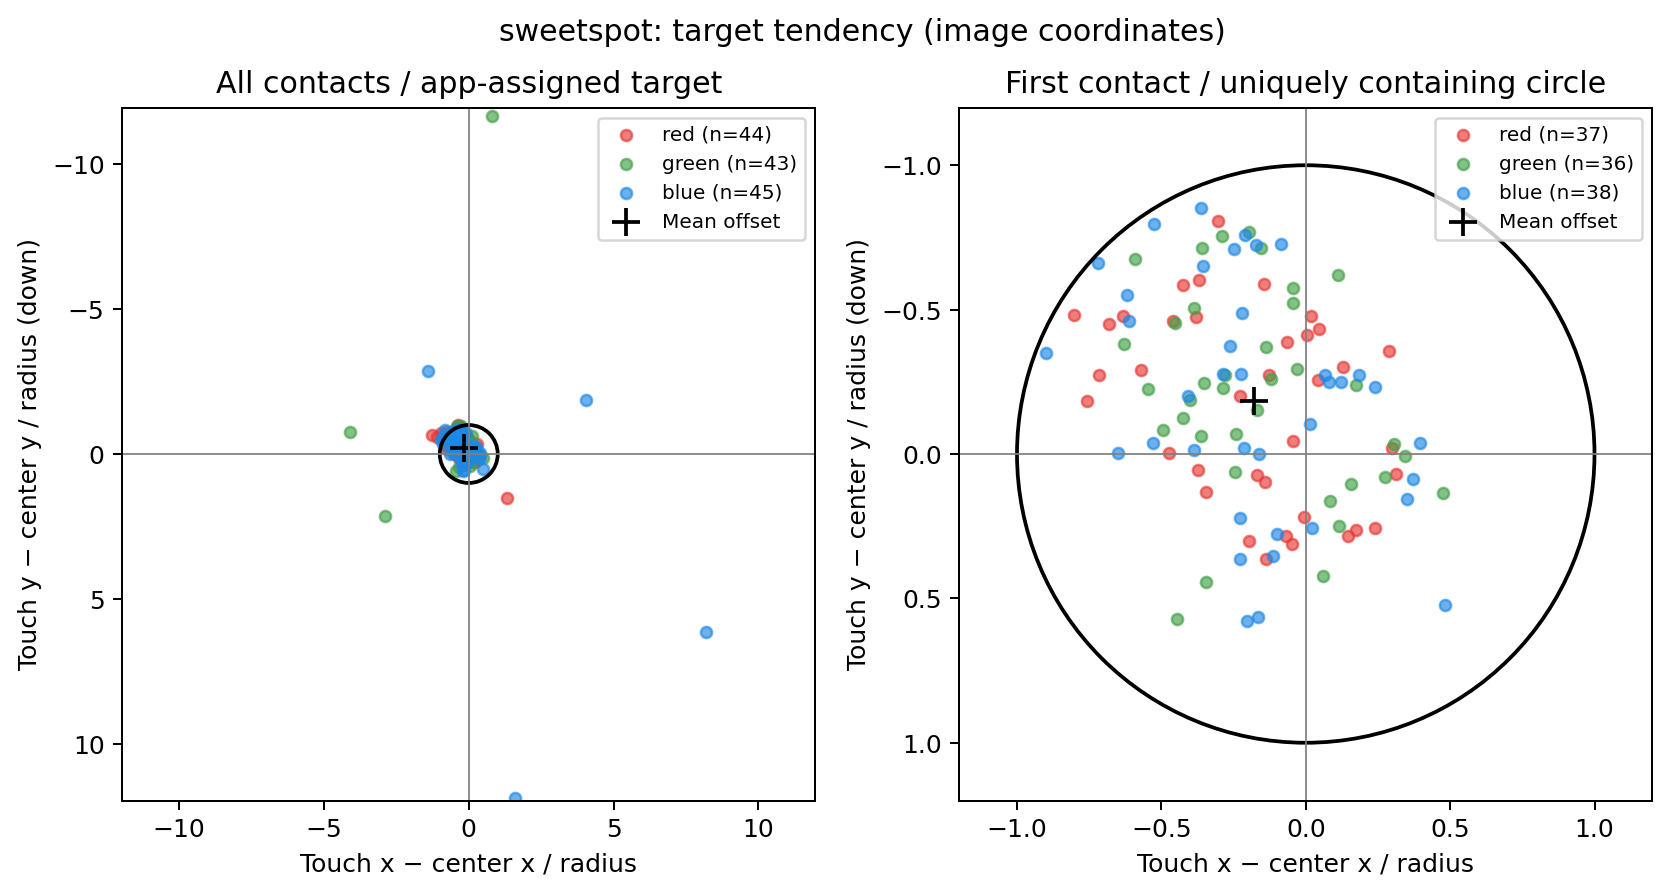

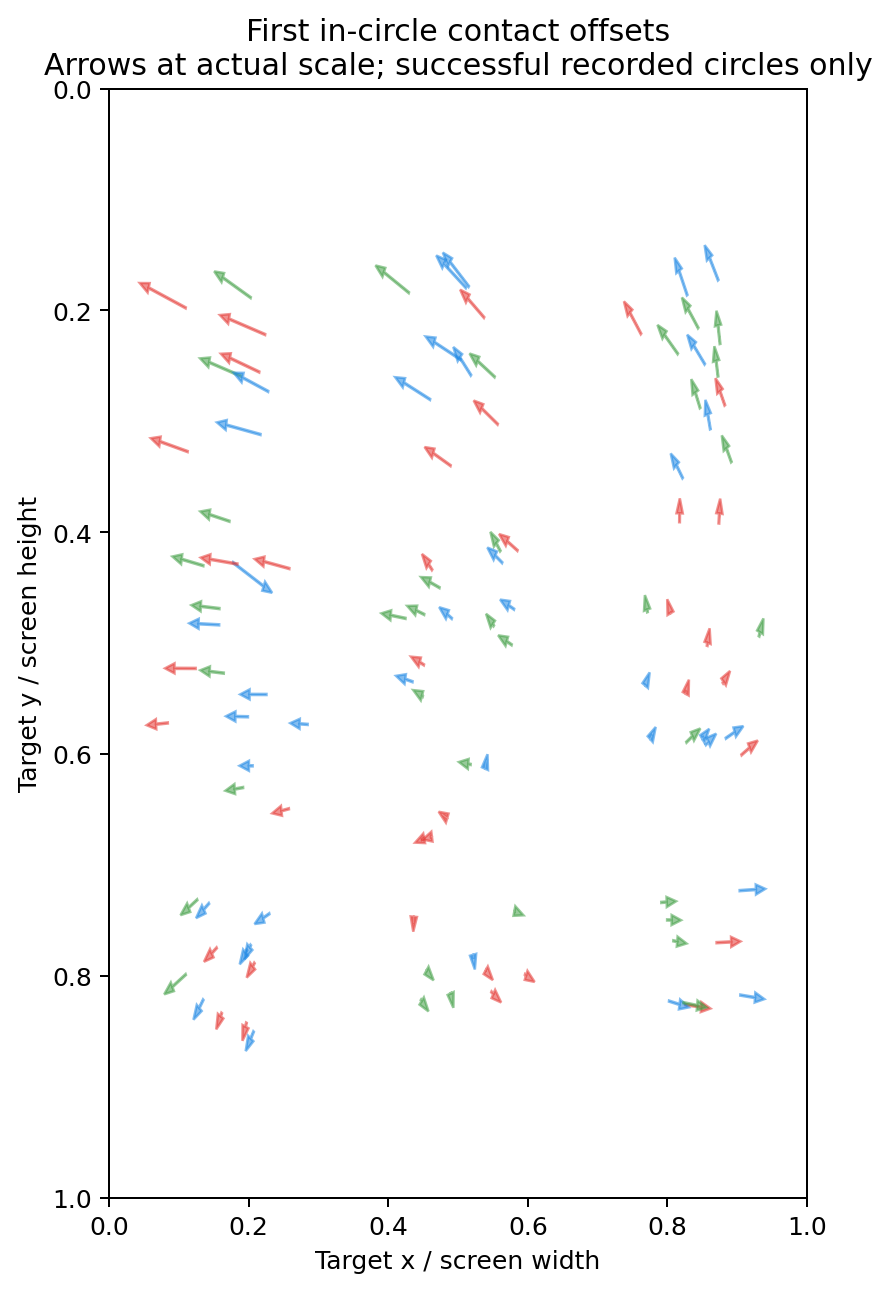

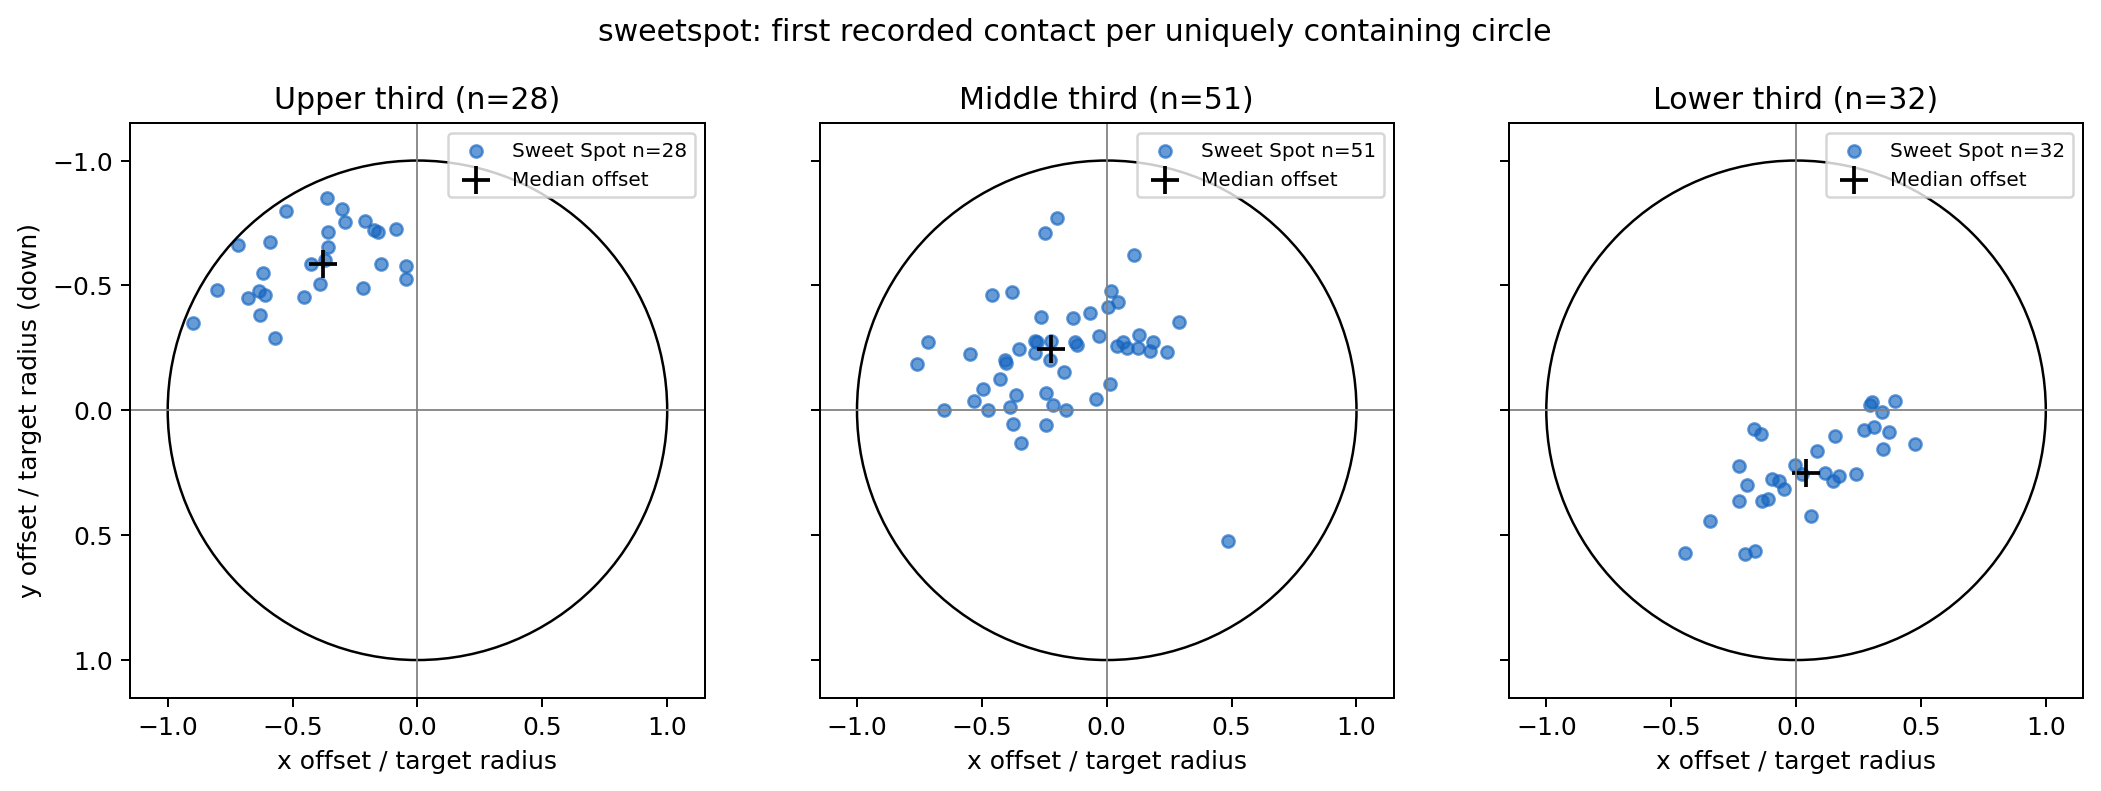

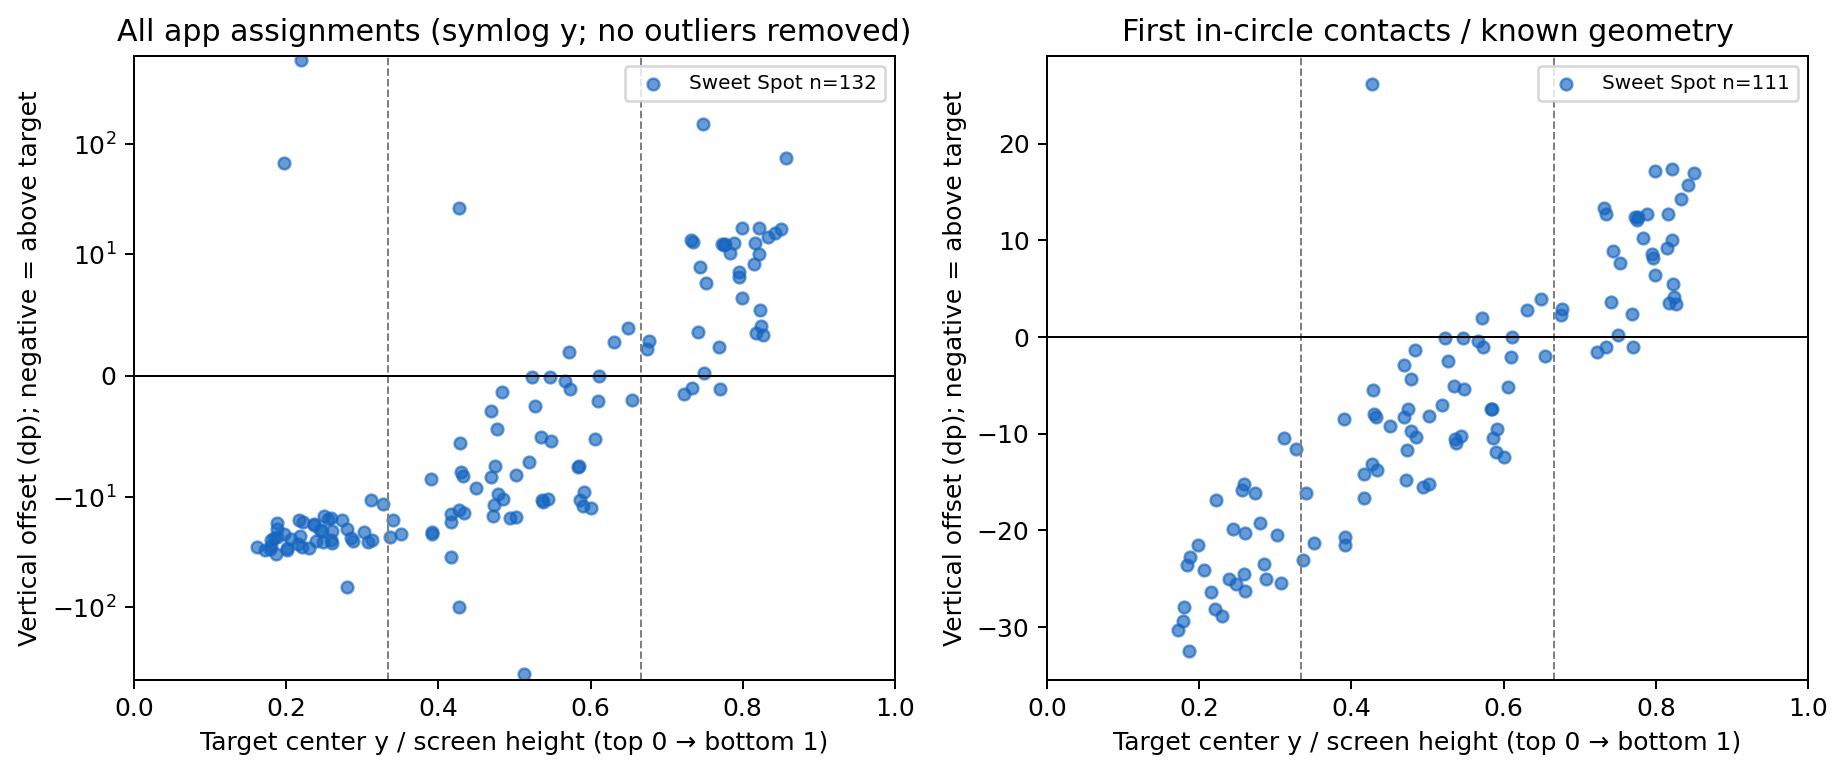

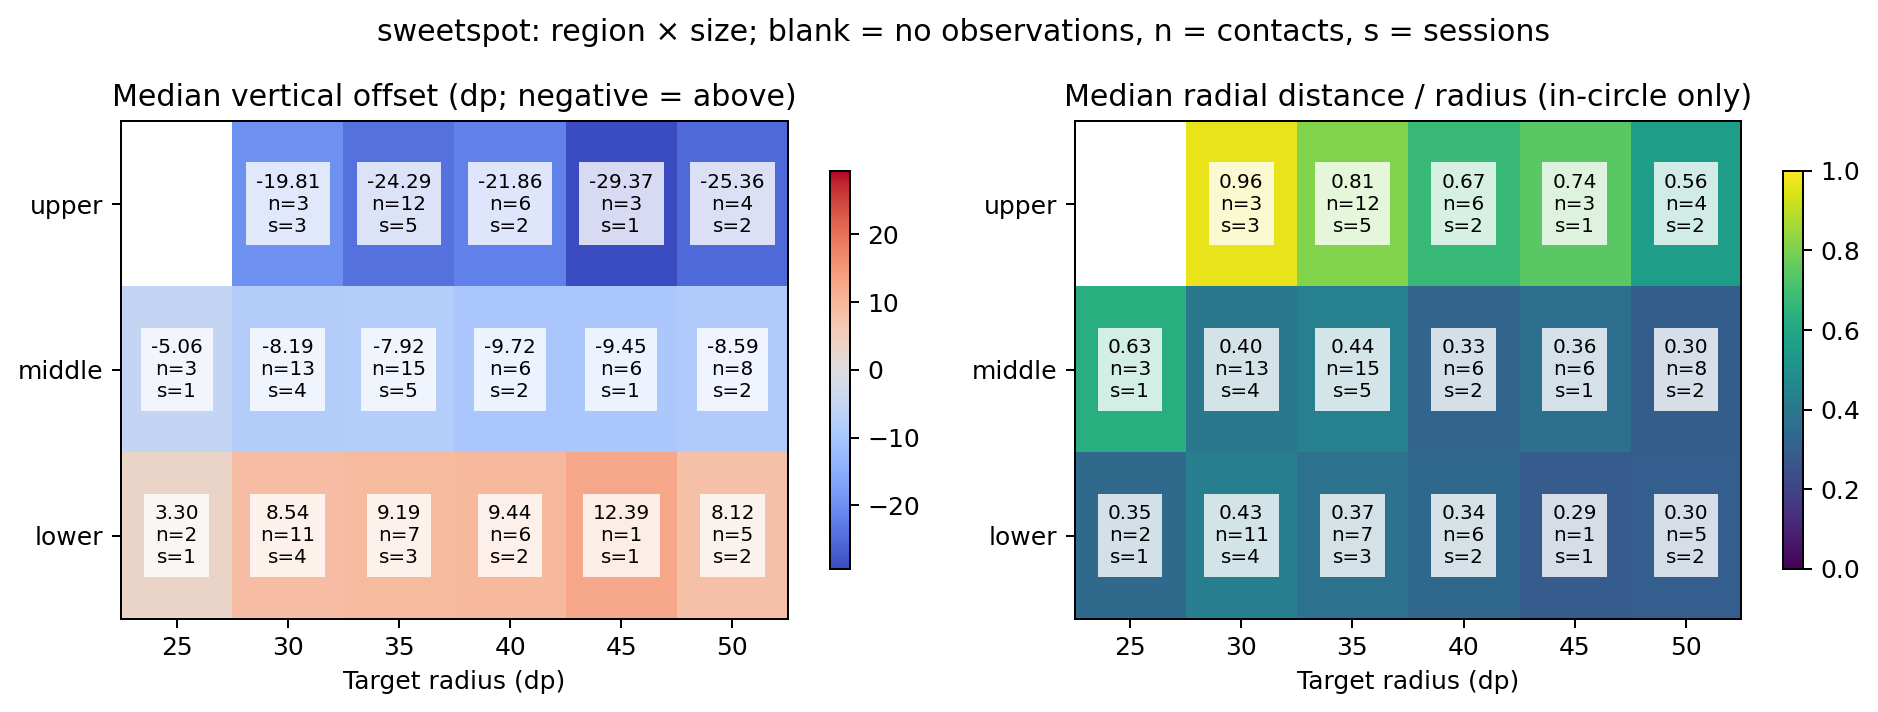

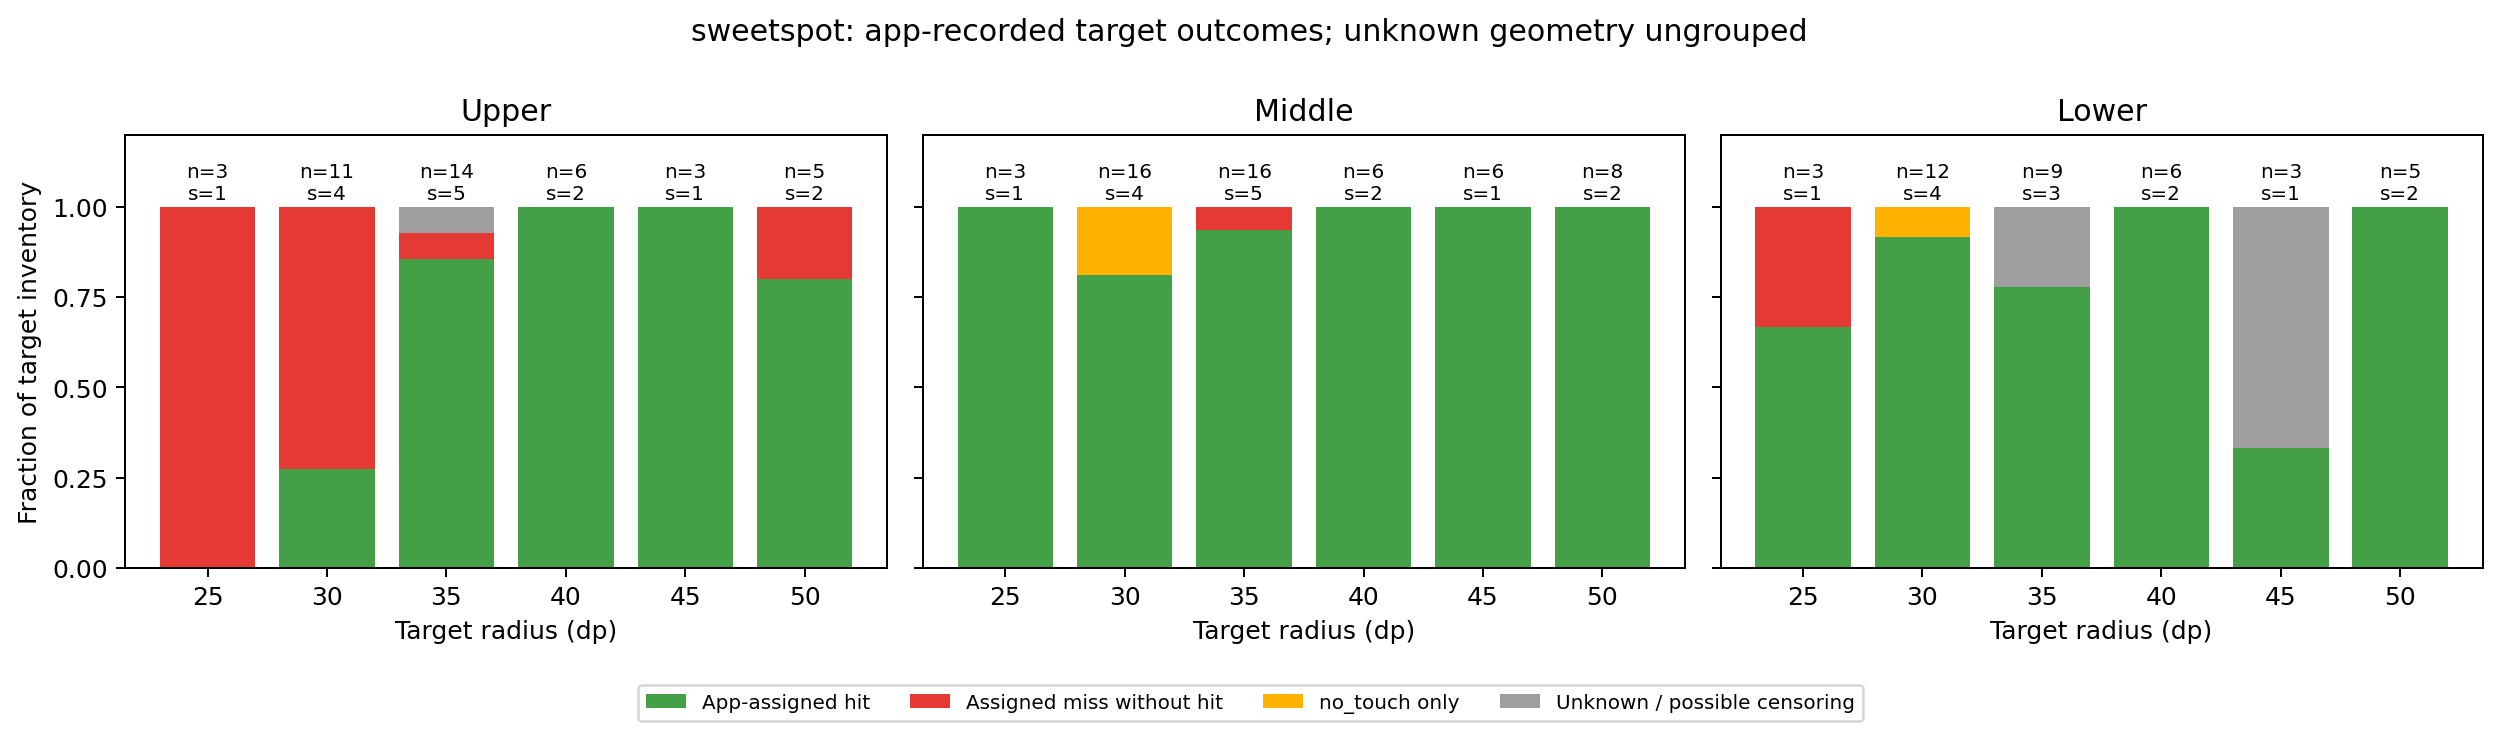

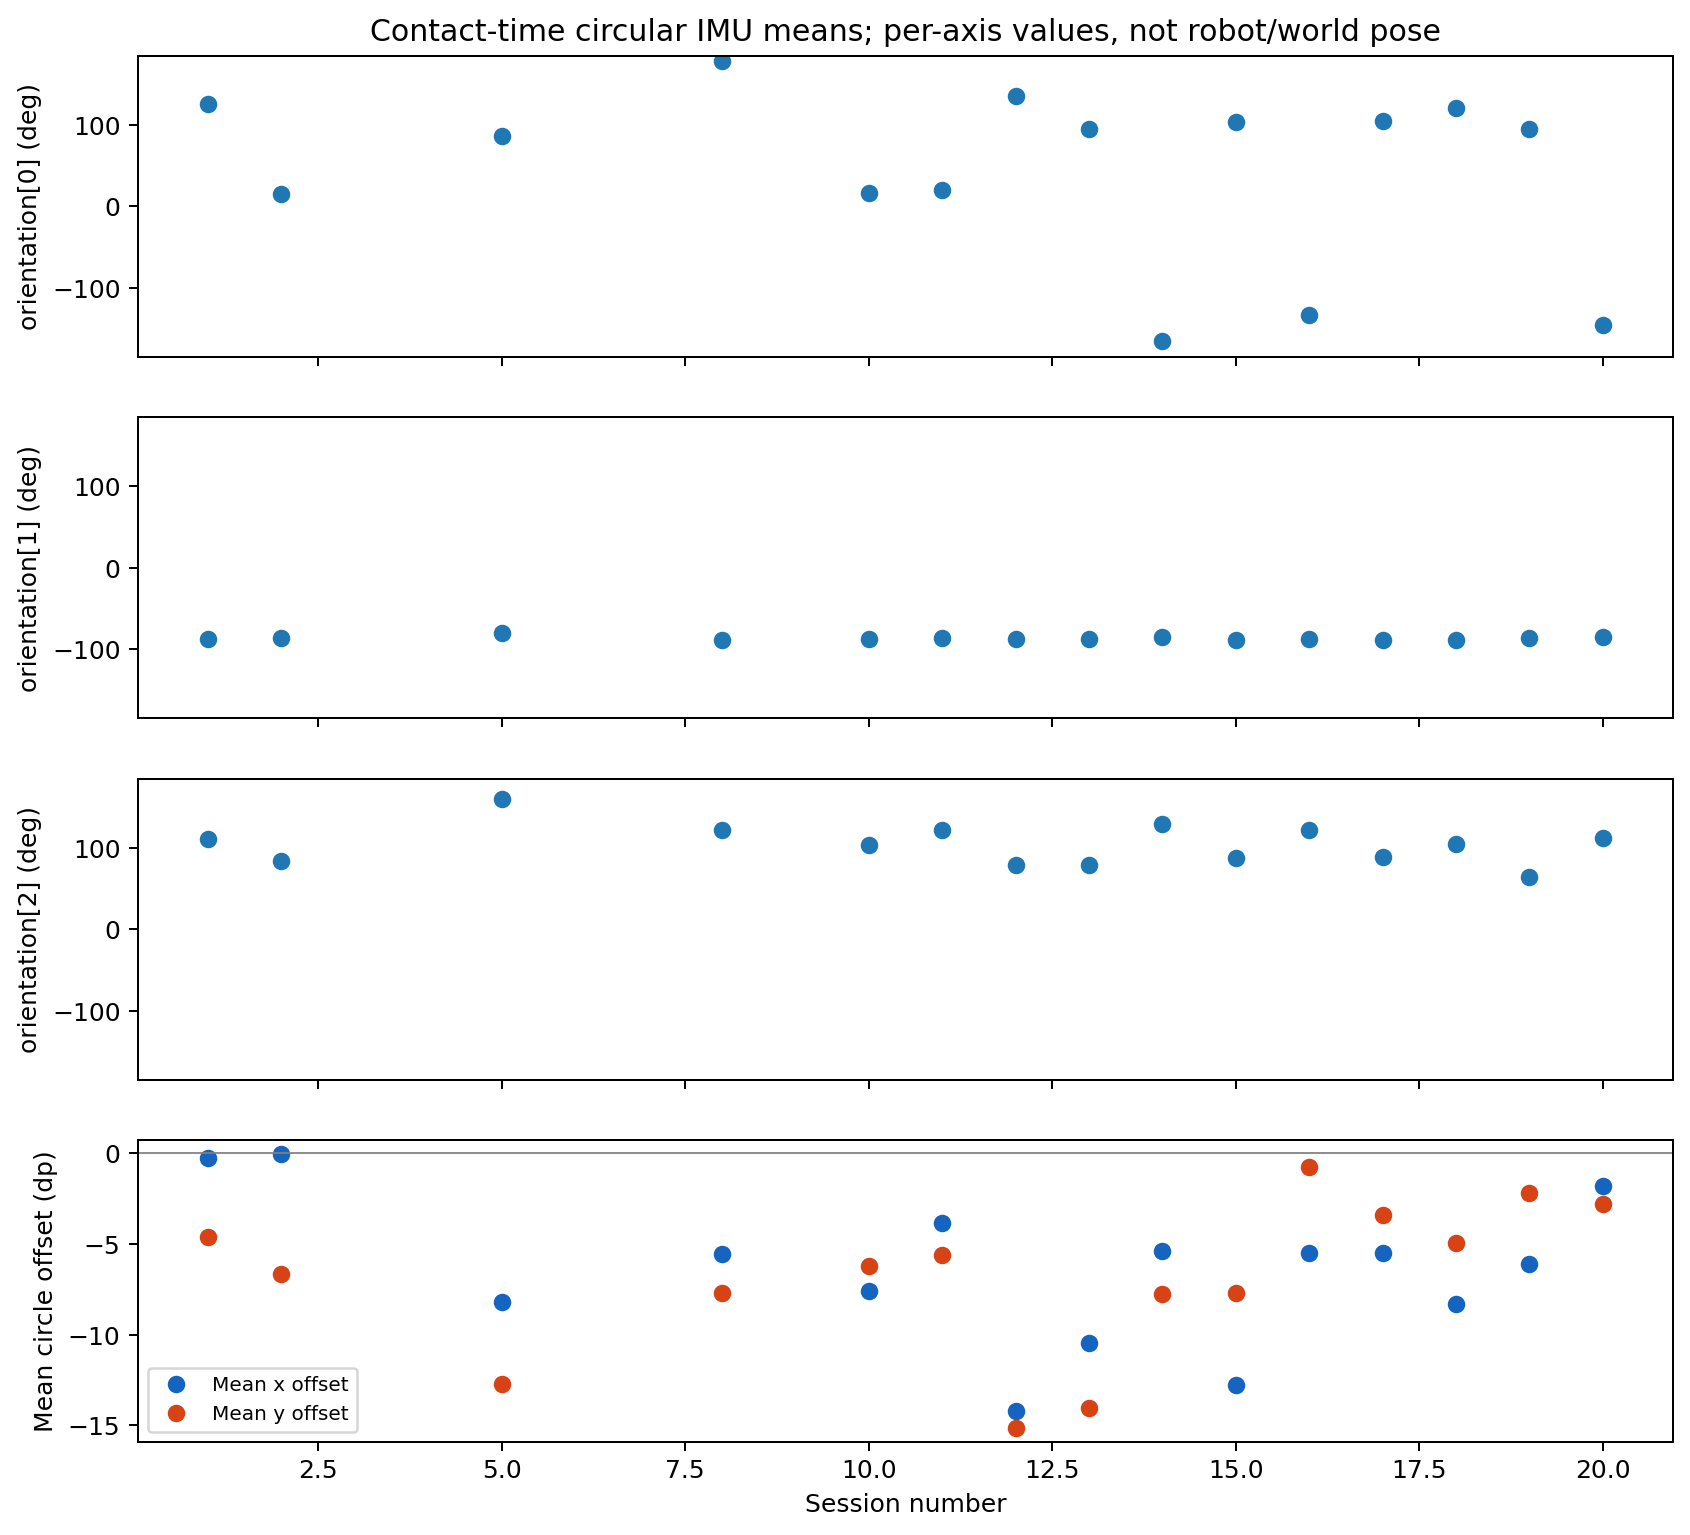

# Random Poses: contact tendency and observation limitations

- Sessions analyzed: **7**; recorded contacts: **105**.
- Original session numbers preserved. Archived sessions: **[2, 7, 8, 10]**; see `data/annotations/random_poses_exclusions.csv`.
- App-reported hits: **101/105 = 96.19%**, including repeats.
- App-assigned target hit coverage: **88/102 = 86.27%**.
- Distinct circles uniquely containing a recorded contact: **88/102** (geometric observation, not intended-action accuracy).
- Targets with any event/geometry: **92/102**. Sessions without all expected target IDs: **[6]**.
- Targets without any record: **10** (unknown outcomes, not failures).
- Hit fraction among targets with a record: **88/92 = 95.65%** (selection-dependent).
- Sessions with all expected IDs recorded: **6**; target coverage **82/84** (not independently verified robot completion).
- Rapid repeated-location pairs: **2**; explicit app completed-target repeat contacts: **13**.
- Contacts inside exactly one different circle than the app-assigned target: **0**.
- Legacy count-ceiling-compatible sessions: **none**.

## Target tendency

First recorded contact per uniquely containing circle: **88** observations across **7** sessions.
Mean offset: **x -1.28 dp; y -10.92 dp**.
Session-balanced mean: **x -1.89 dp; y -10.70 dp**.
Contacts above center: **75.0%**; left of center: **53.4%**.
Median radial error: **0.495 radii**; 90th percentile: **0.820 radii**.

Positive x points right; positive y points down. The unit circle is the target boundary.
dp is derived from each target's logged px/dp ratio, not physical millimeters.
`target_tendency.csv` includes radius/color/region and region × radius strata, all app assignments (including misses),
all uniquely contained contacts, first-per-circle observations, and two repeat-exclusion sensitivities.
First-per-circle is a spatial sampling rule, not a reconstructed robot action or first intended attempt.
The in-circle tendency is conditional on recorded success; it excludes outside/ambiguous contacts and has boundary truncation.
Means are descriptive. Contacts are clustered by session; no independent-event significance test is applied.

## Double contacts and app censoring

Raw app outcomes are never overwritten. Geometry is only reconstructed from logged target circles.
A unique containing circle is identifiable spatially, but does not prove robot intent; missing circles cannot be reconstructed.
Legacy sessions with rapid repeated locations, a contact count equal to effective target count,
and incomplete hit coverage are marked **compatible with the count ceiling**, not confirmed censored trials.
Unresolved targets in those sessions are marked `possible_ceiling_censoring`; no later hit is imputed.
`no_touch` is an app/operator observation, not proof of a physical miss. Missing records in incomplete sessions are unknown.
Retain the original fractions as app-recorded outcomes. Use spatial coverage and repeat sensitivities alongside them;
do not report any corrected fraction as robot accuracy. Recover unlogged outcomes only with synchronized robot logs/video
or a separately attributed operator annotation. Neither is available in these exports.
`outcome_sensitivity.csv` additionally separates full-ID sessions and excludes ceiling-compatible sessions,
with all contacts versus rapid-repeat and explicit completed-target-repeat exclusions.
These alternative populations are sensitivities, not replacement truth or independent-action estimates.

## Phone orientation (exploratory)

`sessions_extended.csv` summarizes contact-time `orientation_deg[0..2]` using circular means,
resultant concentration and largest circular deviation, plus accelerometer/gyroscope norm medians.
Null sensor samples are omitted. Manual no-touch timestamps are excluded from these summaries.
These are phone sensor axes as logged: the exporter axis convention, phone-to-holder extrinsic and
reference heading are not established here. They are not calibrated robot/world roll, pitch and yaw.
Near an Euler singularity, heading and roll may change even for a similar phone attitude;
contact-time acceleration includes motion/impact. The IMU plot describes sample variation only.
Random target placement in app configuration does not identify a random robot pose. The Random Poses
random-holder condition comes from the operator's description and remains a dataset-level annotation.
Sweet Spot radius, collection time, app behavior and holder conditions differ from the later dataset;
their fractions cannot demonstrate a causal improvement or deterioration.

# random_poses: screen region and target size

Regions are fixed thirds of **logged screen height**, assigned using the **target center**:
upper [0, 1/3), middle [1/3, 2/3), lower [2/3, 1]. They are not thirds of the app's target-placement area.
Contacts never change region merely because their touch coordinate crosses a boundary.
Offsets are in dp (not mm) and target radii; negative vertical offset means above the center.

## First contact per uniquely containing circle

This population describes recorded in-circle placement, not all intended robot attempts.
Outside contacts are kept separately in the app-assigned populations below.

| Region | Contacts | Sessions | Mean x (dp) | Mean y (dp) | Median y (dp) | Median distance (dp) | Median distance / radius | Above center |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| lower | 22 | 6 | +9.39 | +2.68 | +3.81 | 12.45 | 0.311 | 40.9% |
| middle | 35 | 7 | -0.65 | -9.86 | -11.32 | 15.54 | 0.389 | 77.1% |
| upper | 31 | 7 | -9.58 | -21.77 | -24.82 | 29.17 | 0.729 | 96.8% |

## All app-assigned contacts (hits and misses)

| Region | Contacts | Sessions | Mean y (dp) | Median y (dp) | Median distance / radius |
|---|---:|---:|---:|---:|---:|
| lower | 23 | 6 | +3.11 | +4.01 | 0.320 |
| middle | 39 | 7 | -23.24 | -13.83 | 0.414 |
| upper | 43 | 7 | -24.15 | -27.13 | 0.761 |

App assignments can differ from the physically containing circle after repeated touches.
`region_size_contacts.csv` includes sensitivities removing rapid-repeat second events,
explicit completed-target repeats, or either repeat flag. All original contacts remain available.

## Target outcomes by region

Each target is counted once within its original dataset/session. Unknown/censoring outcomes are kept separate.
`no_touch` is an app observation, not proof of a physical failure. Missing geometry receives region `unknown`.

| Region | Targets | App-assigned hit | Assigned miss without hit | no_touch only | Unknown/censoring |
|---|---:|---:|---:|---:|---:|
| upper | 32 | 31 | 1 | 0 | 0 |
| middle | 38 | 35 | 2 | 1 | 0 |
| lower | 22 | 22 | 0 | 0 | 0 |
| unknown | 10 | 0 | 0 | 0 | 10 |

## Region × size

`region_by_size.png` shows median vertical offset in dp and median radial distance divided by radius,
with contact/session counts for each combination. `region_size_outcomes.csv` provides the corresponding
target inventory. `target_outcomes_region_by_size.png` also includes combinations with zero recorded hits,
showing target-level app outcomes, no-touch observations and unknown/censoring separately.
Blank placement cells mean no in-circle observations, not zero error or zero success.
A smaller target tolerates less of the same absolute error. Compare dp offsets and normalized distances
together before interpreting any size association. In-circle distributions are boundary-truncated.
Region/size cells with few sessions are descriptive; contacts within sessions are not independent trials.
Random Poses contributes only radius 40 dp. Pooled counts reflect the observed mix of conditions,
not a balanced experiment or causal size/pose effect. The per-condition reports must accompany pooled results.


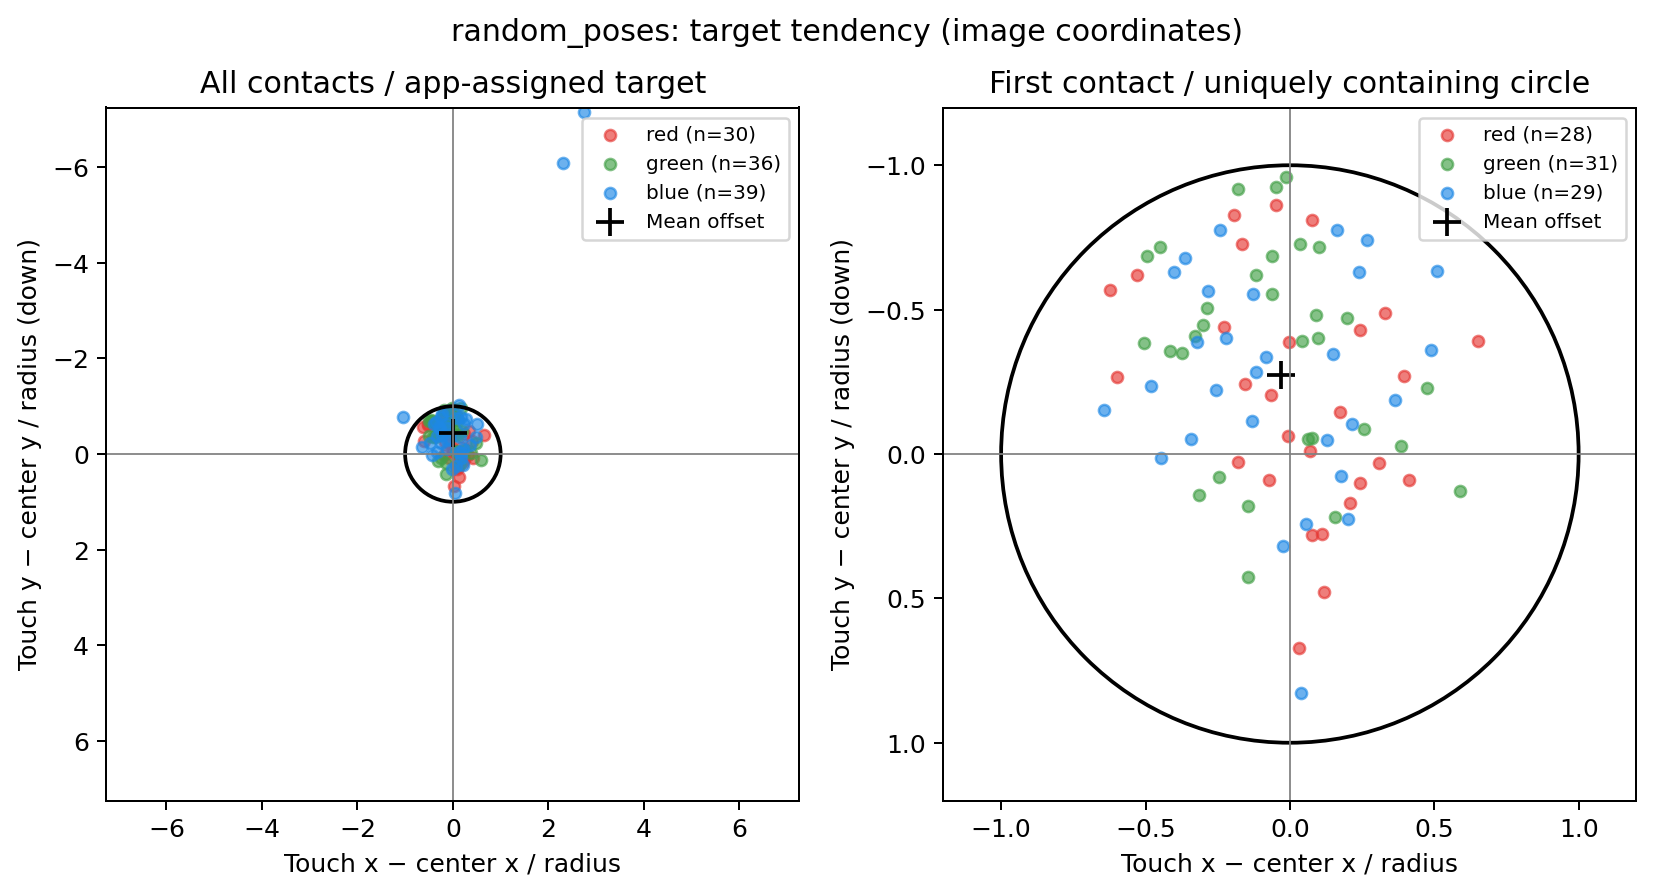

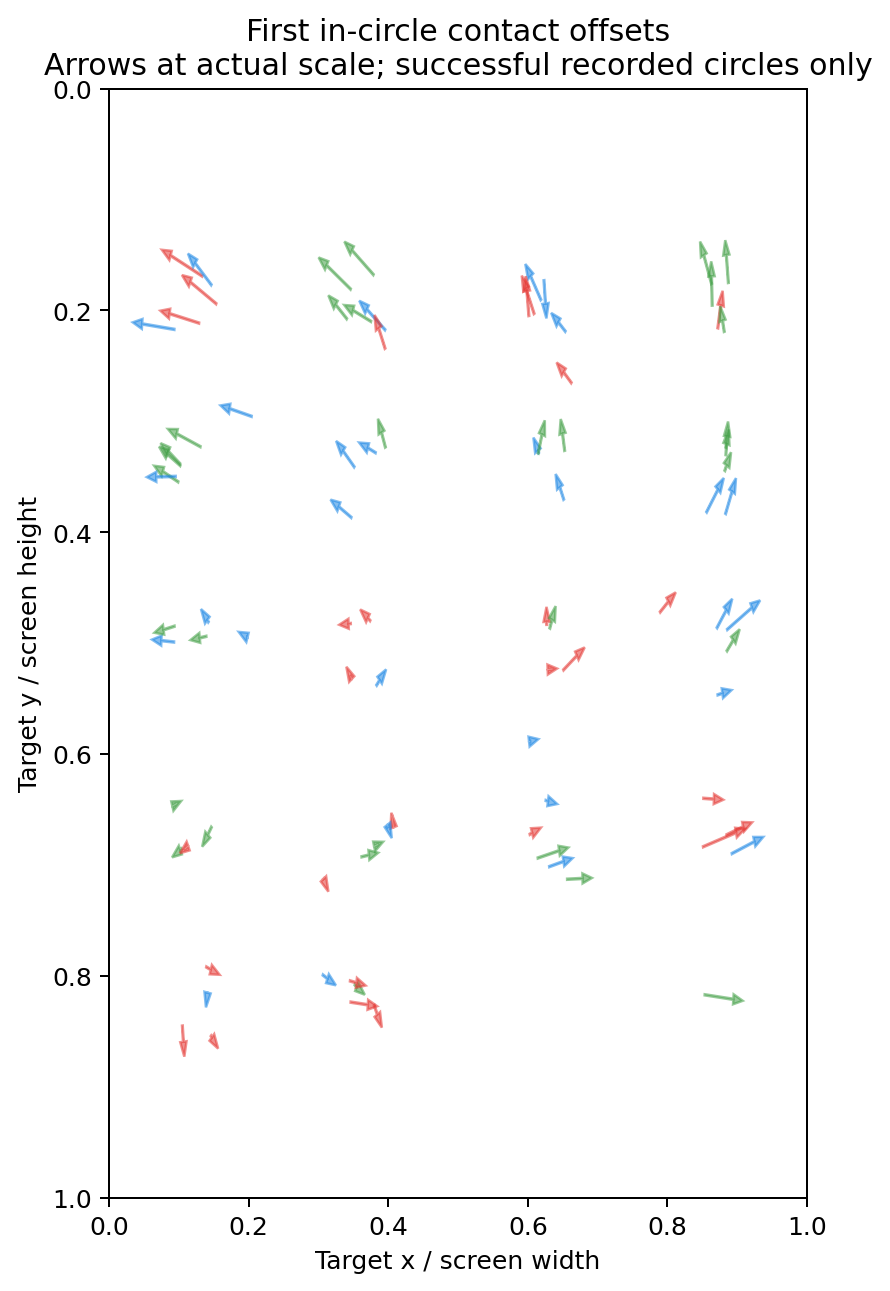

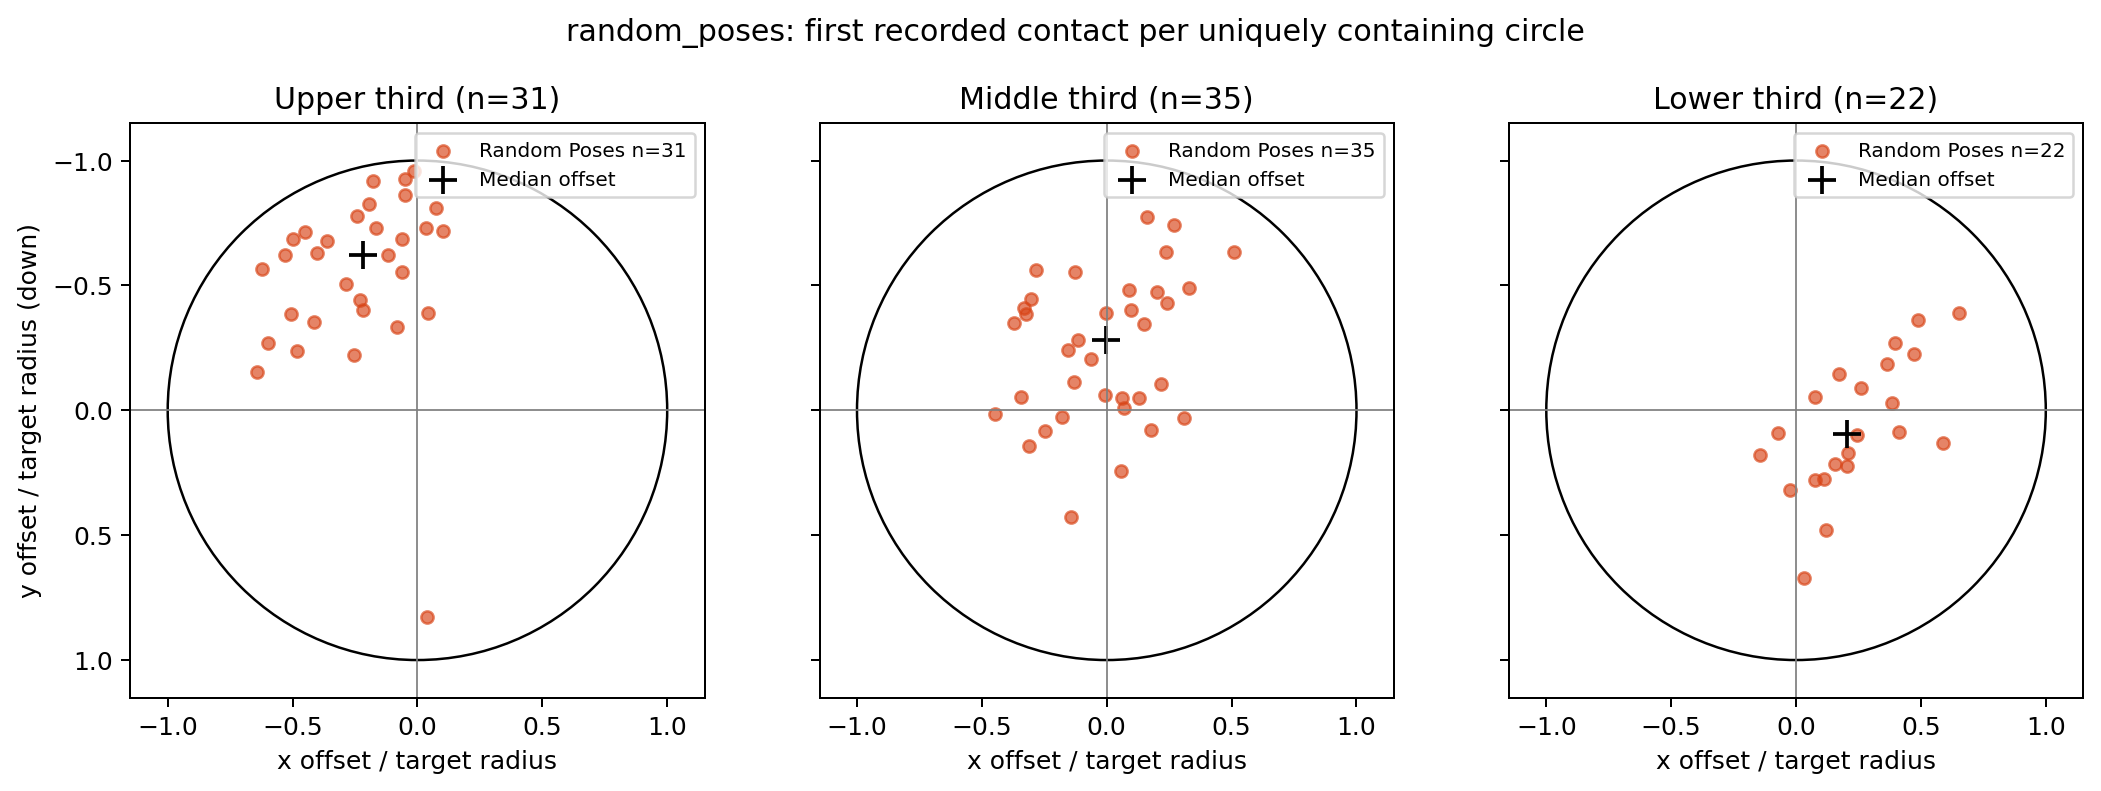

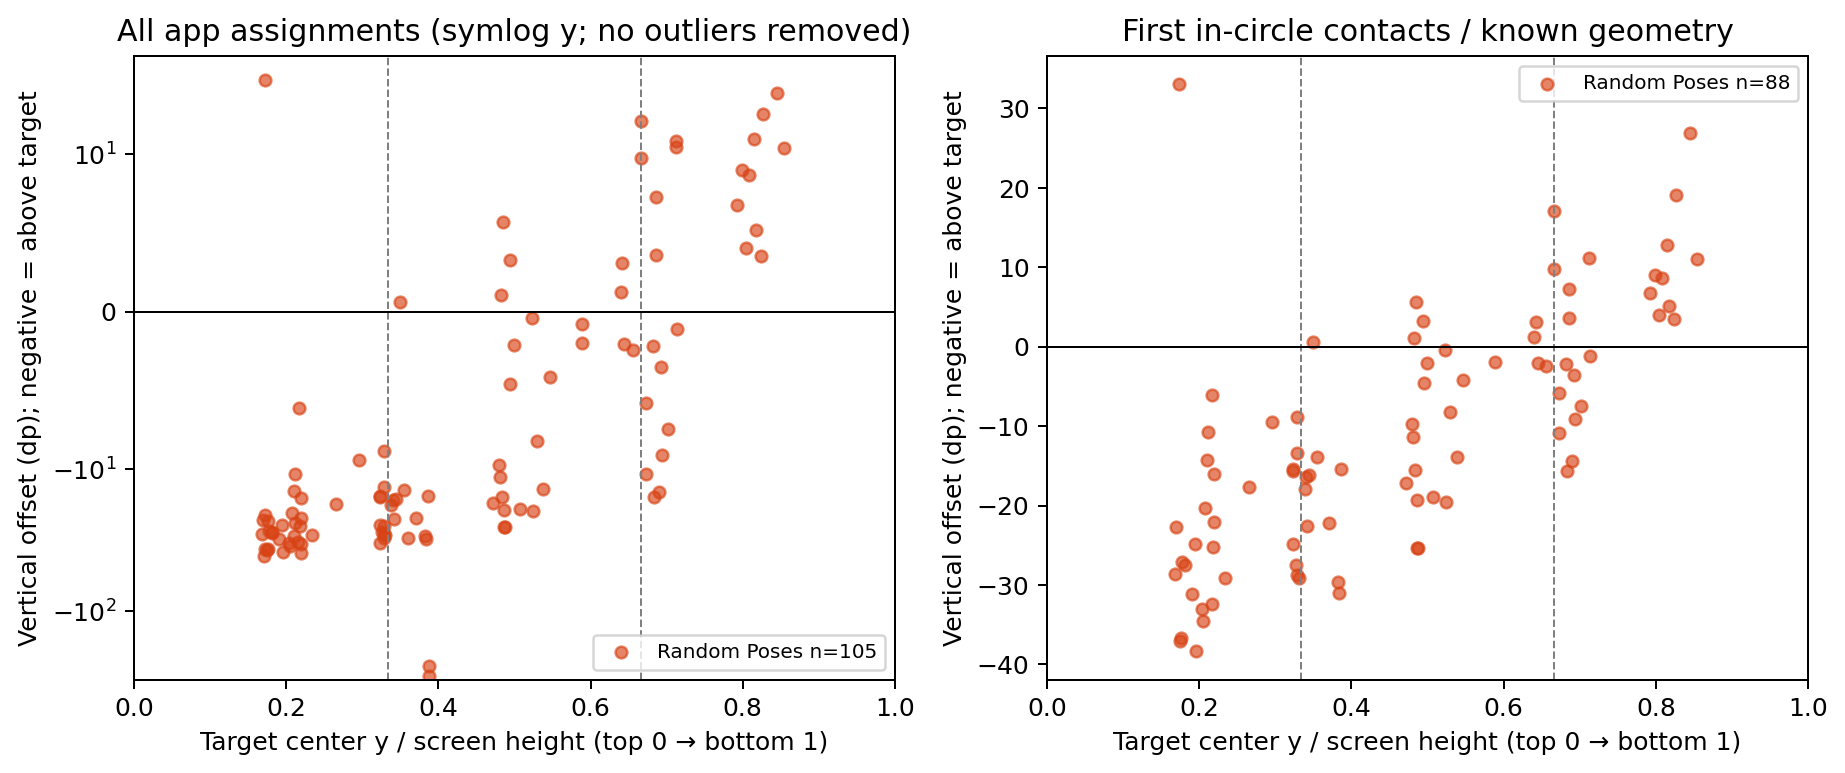

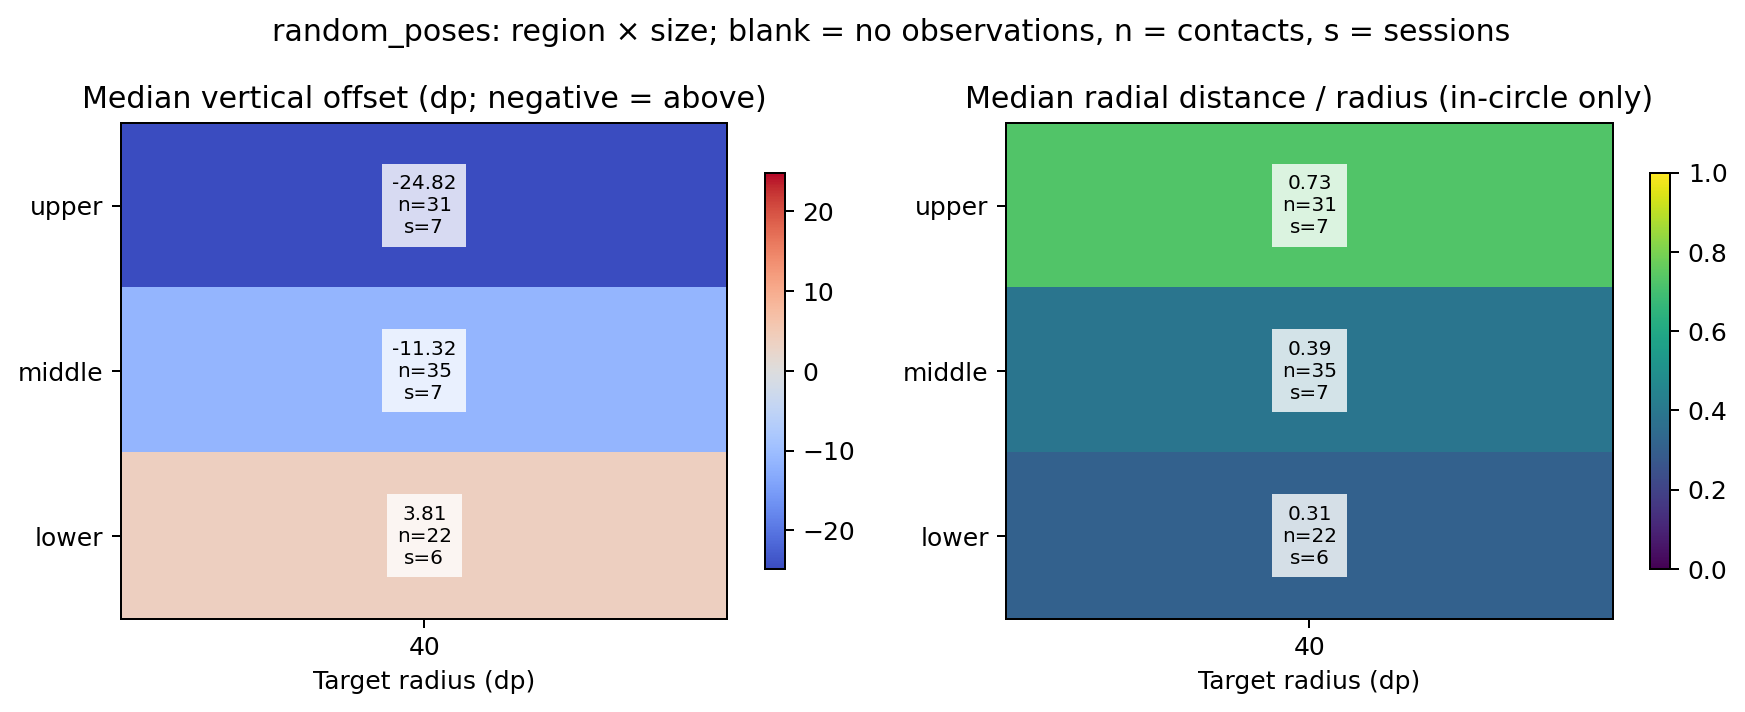

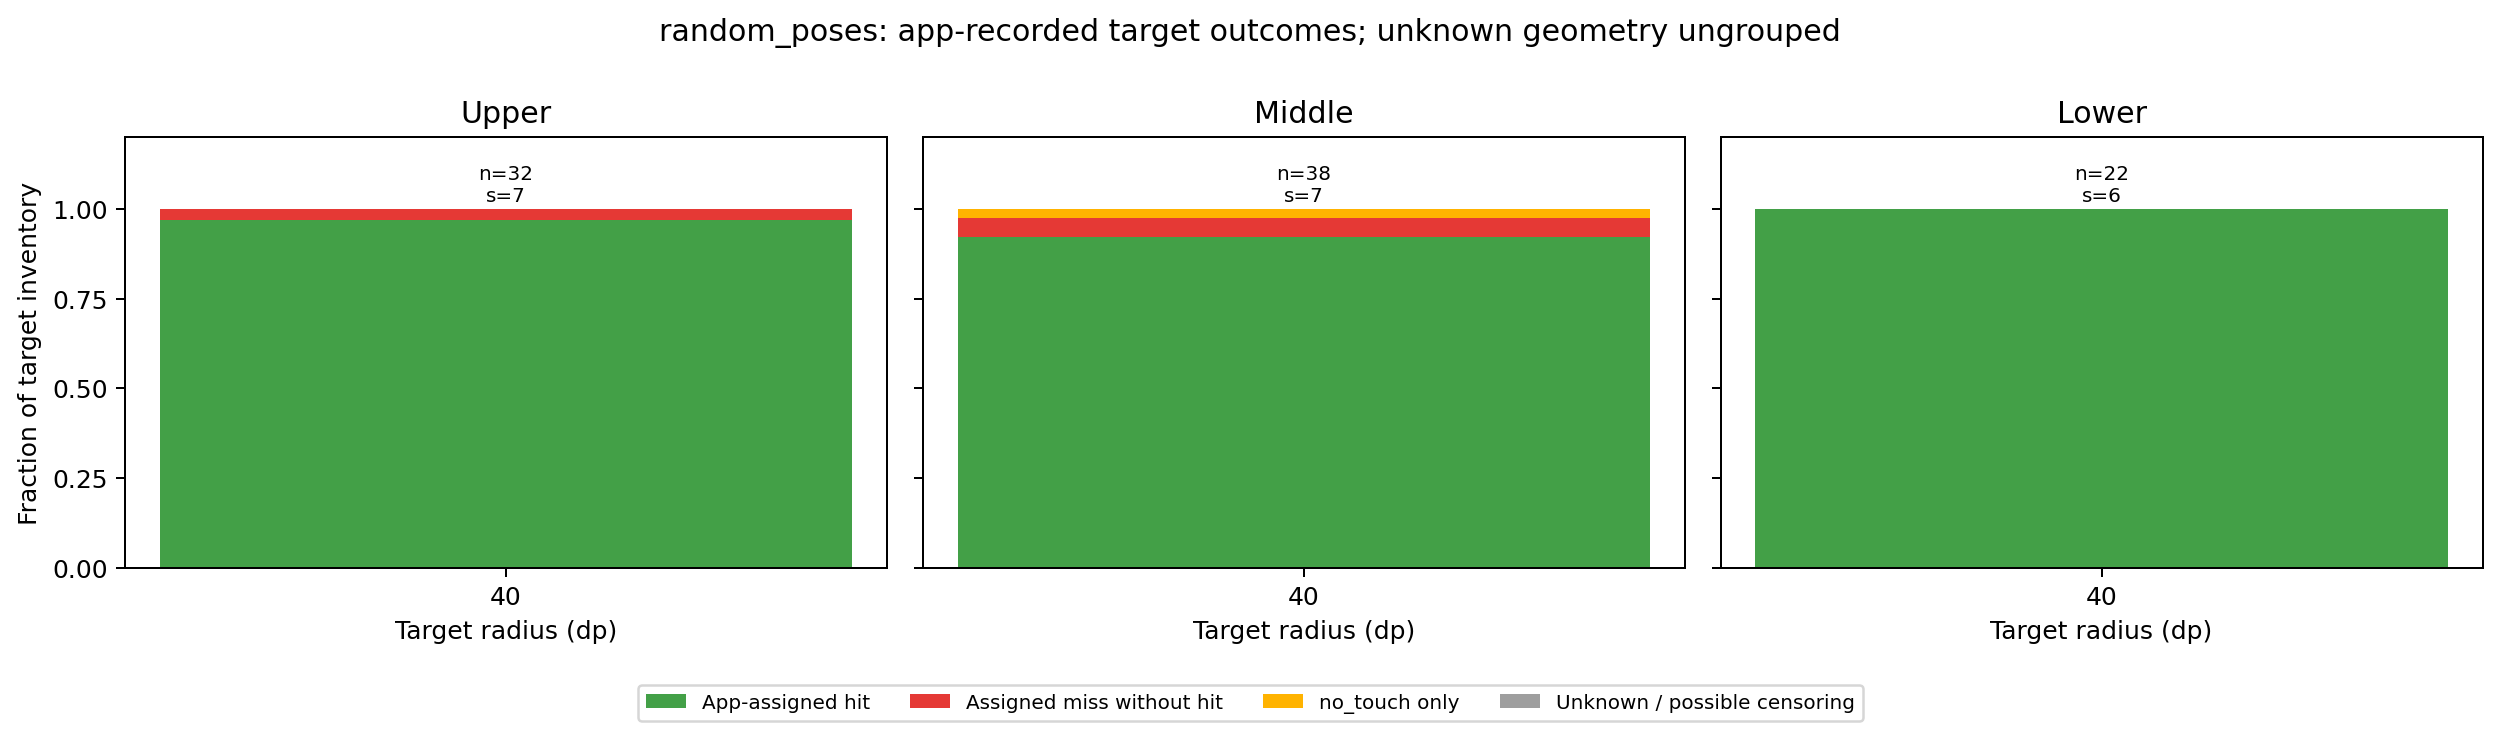

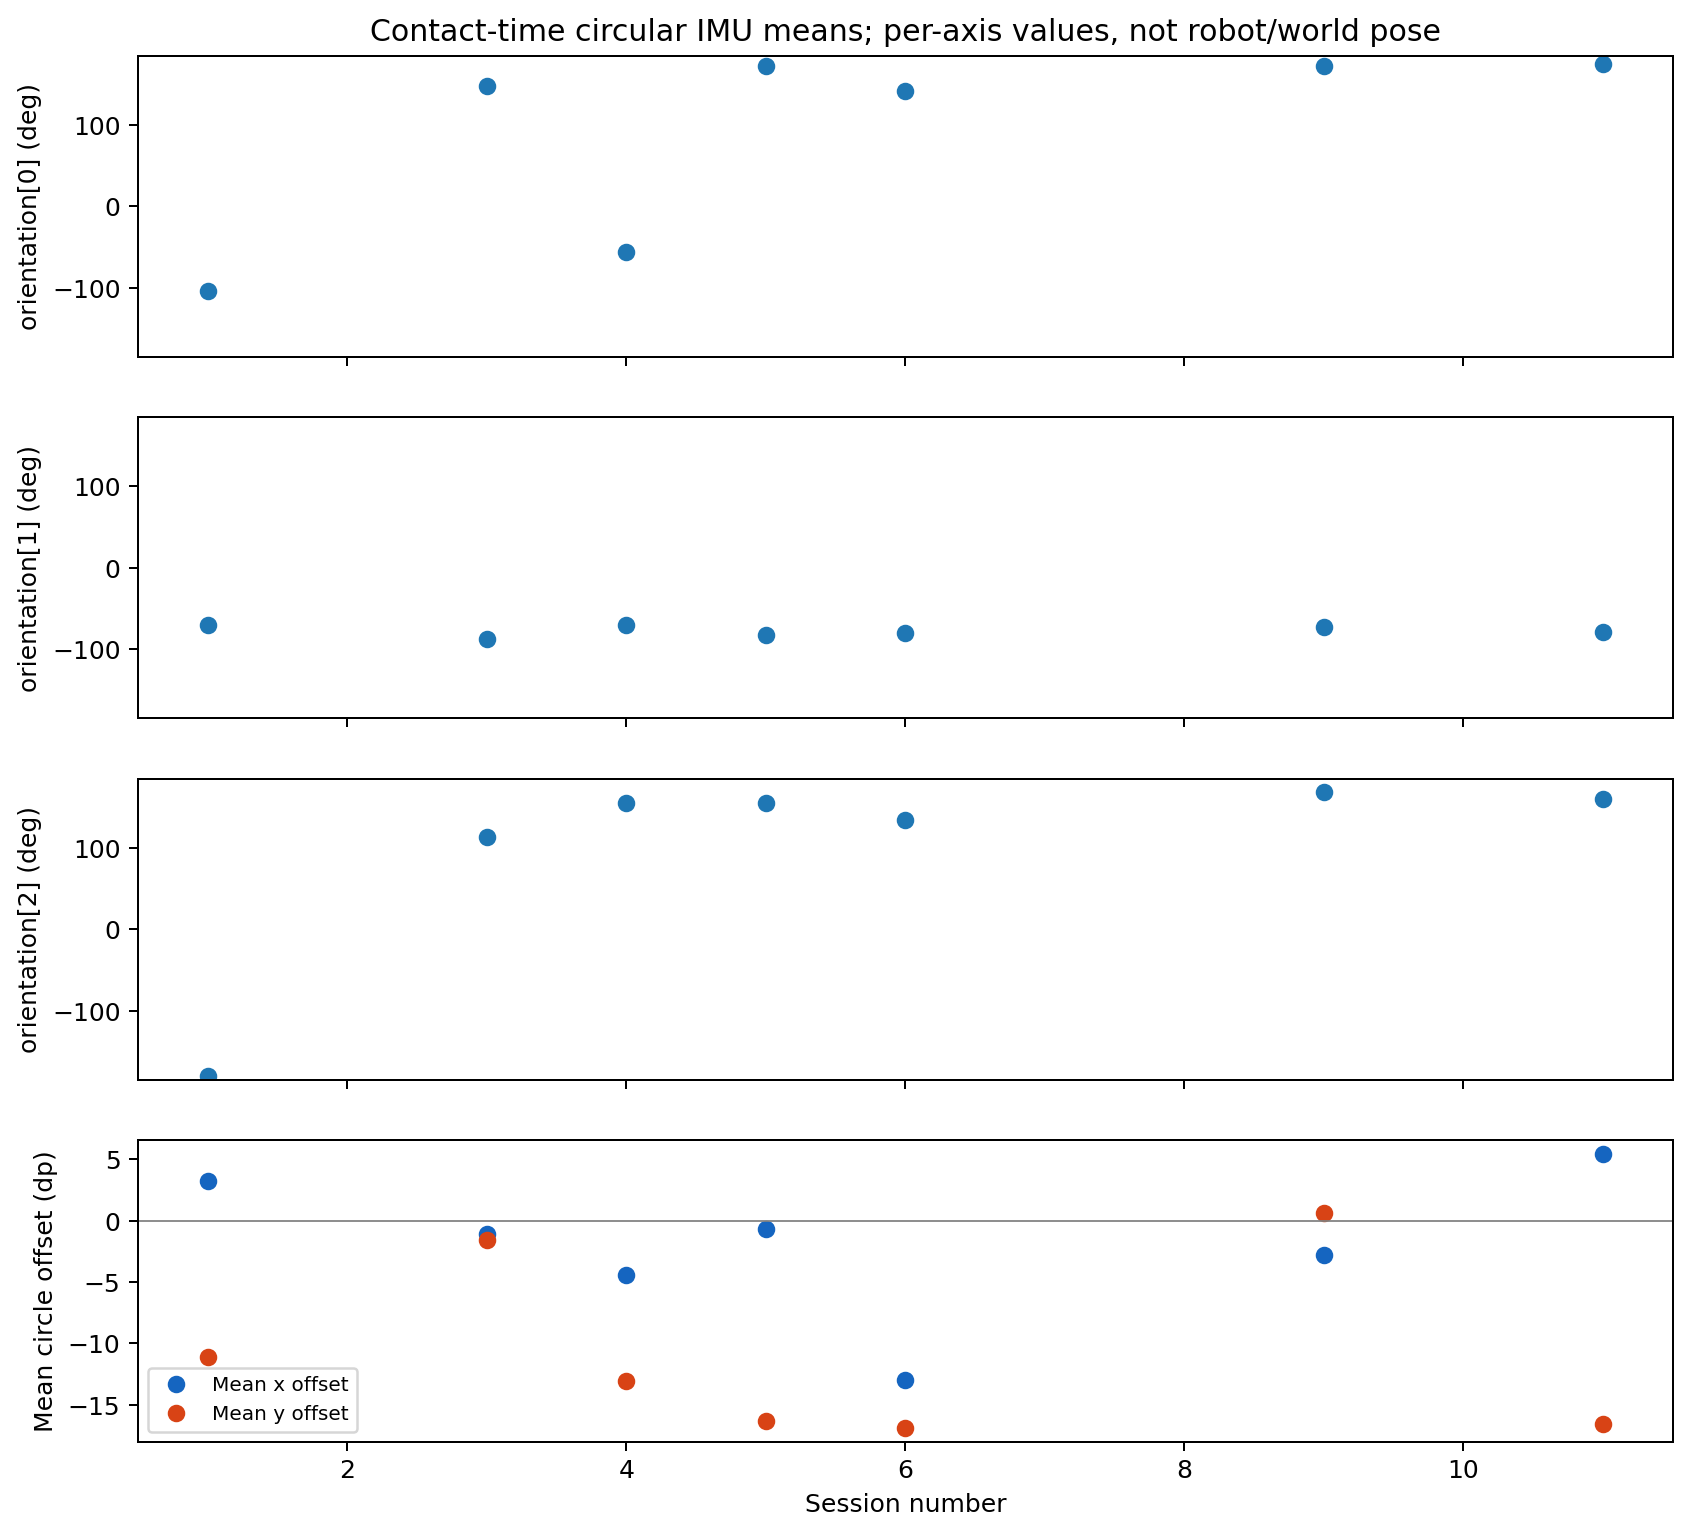

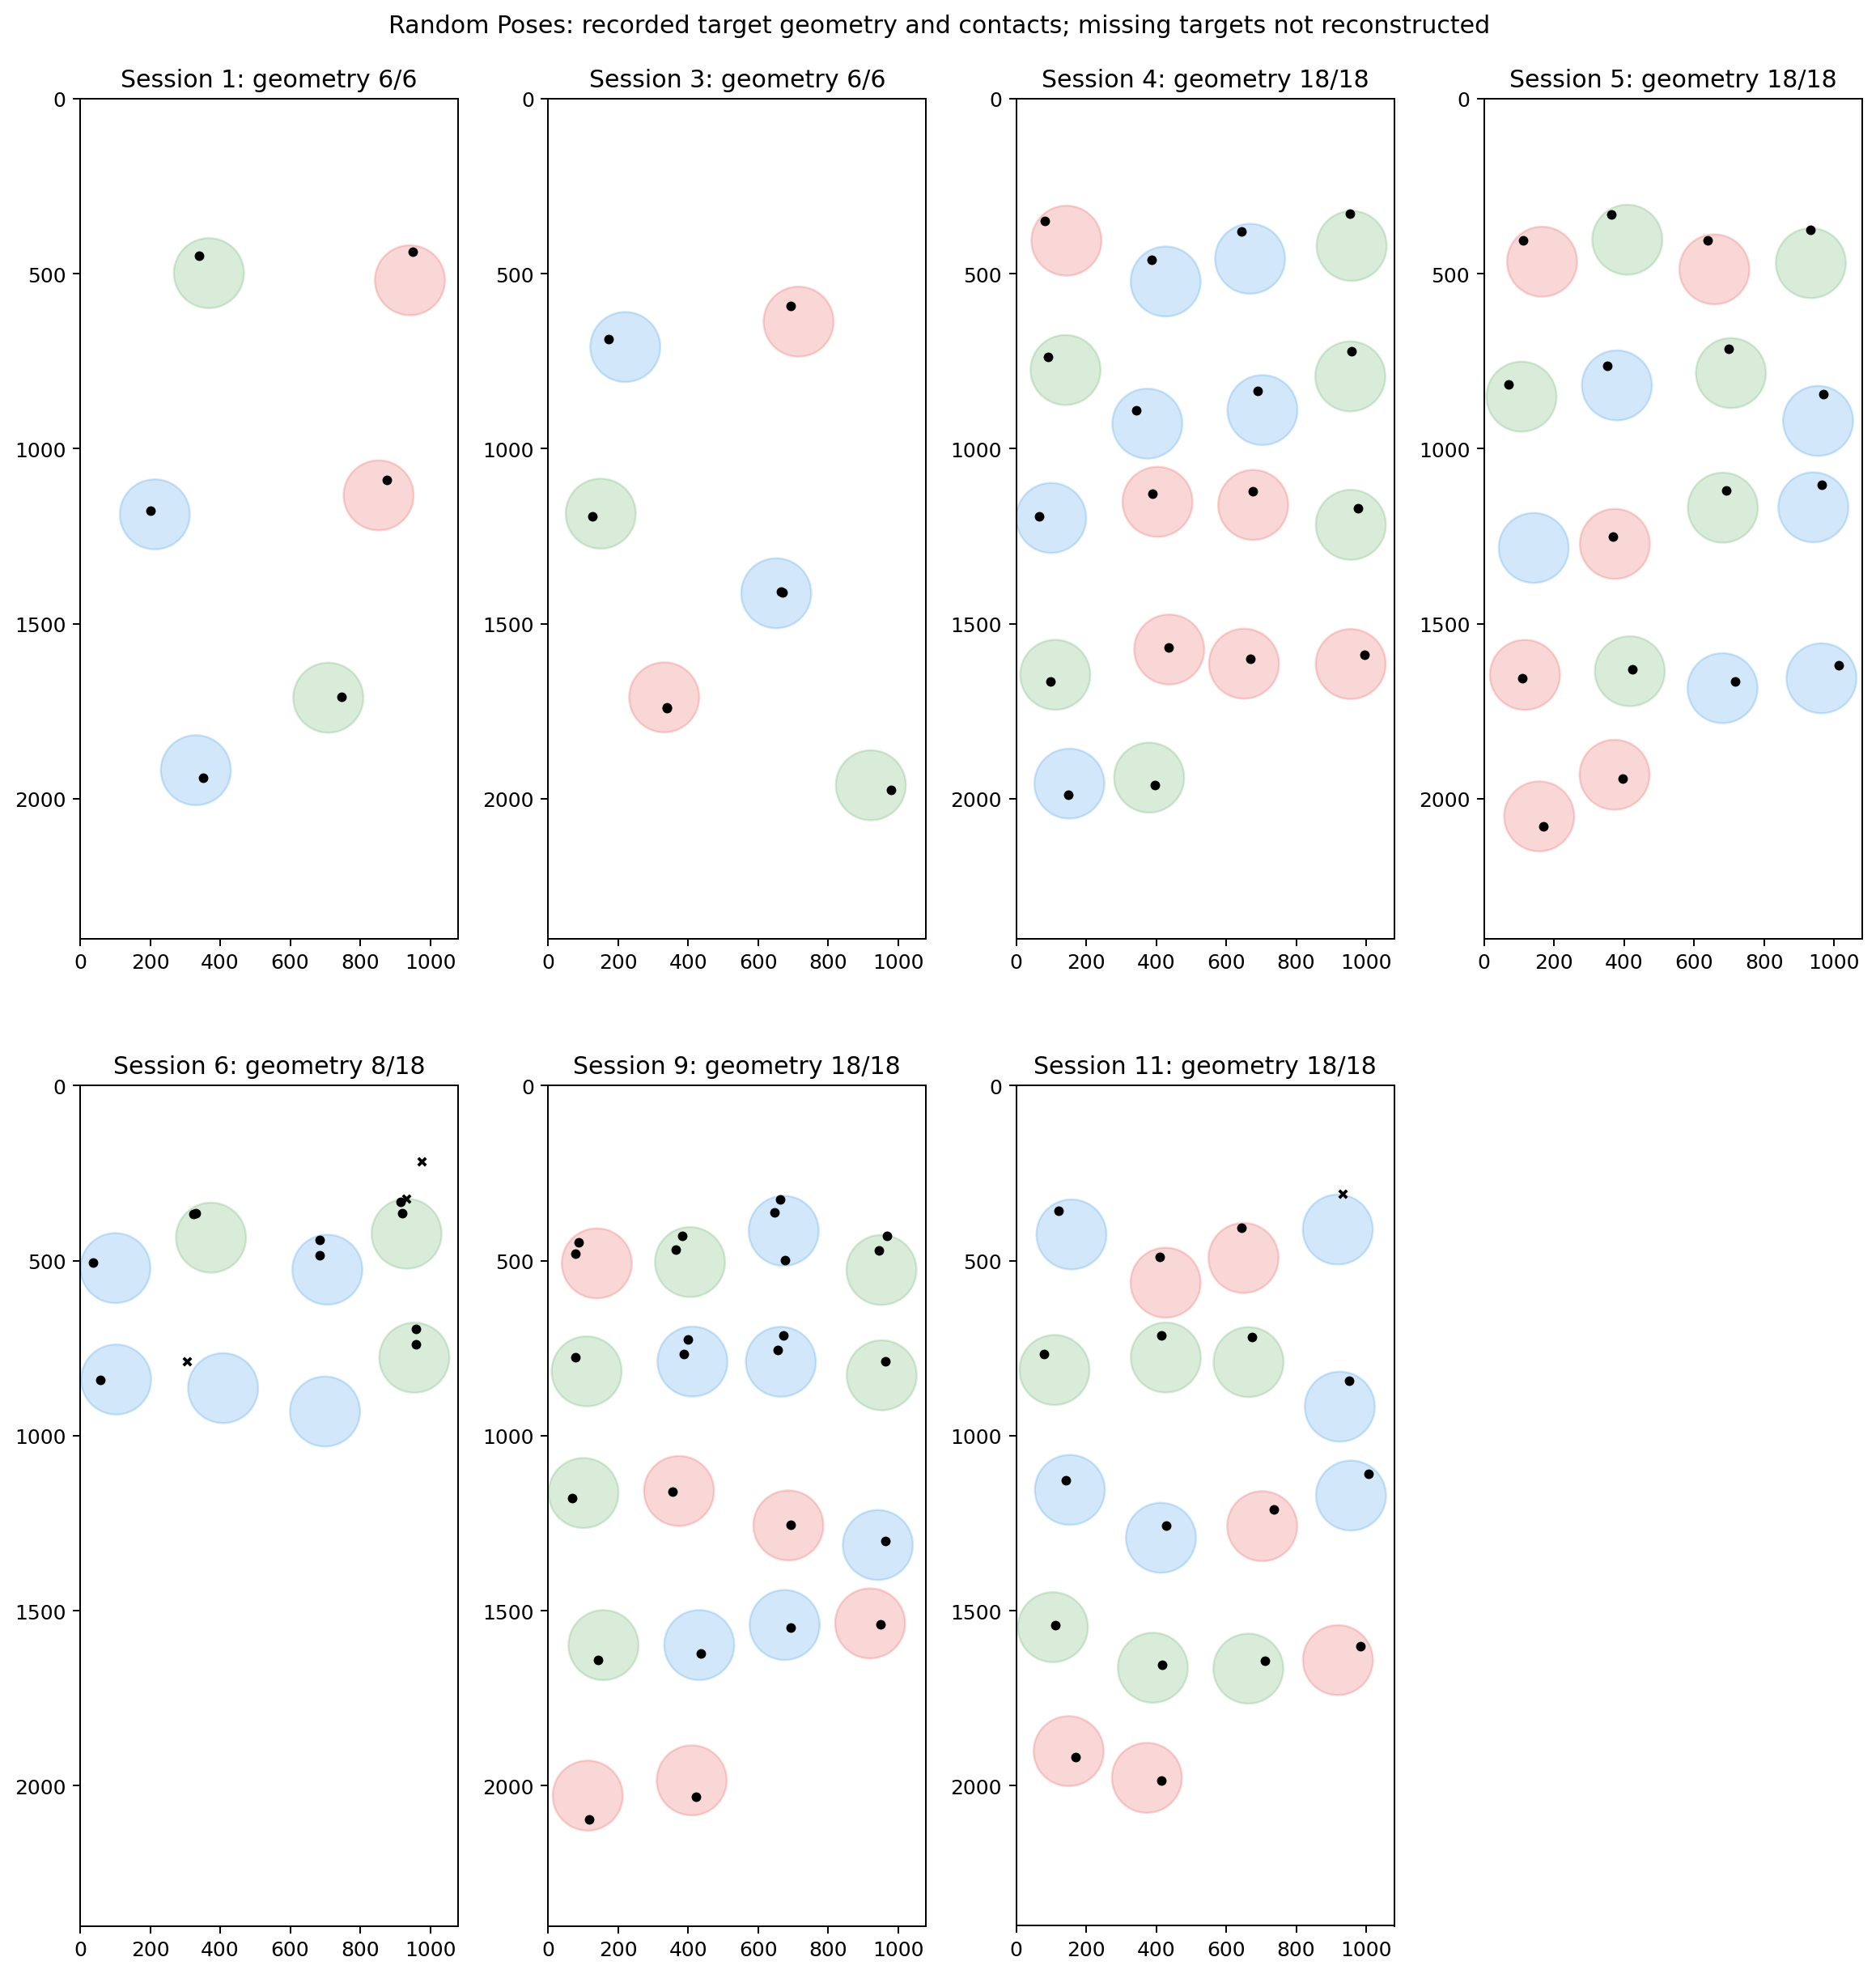

# Overall recorded contacts: Sweet Spot + Random Poses

This section pools **all recorded contacts from retained sessions** in both conditions.
Archived sessions remain excluded. Source dataset, session number, UUID and event ID are kept in every row.
The pooled population reflects the recorded mix of sizes/poses; it is not a balanced experiment.

| Condition | Sessions | Events | Contacts | App hits | App misses | no_touch events | Expected targets | Targets with records |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| sweetspot | 15 | 163 | 132 | 111 | 21 | 31 | 135 | 135 |
| random_poses | 7 | 107 | 105 | 101 | 4 | 2 | 102 | 92 |
| combined | 22 | 270 | 237 | 212 | 25 | 33 | 237 | 227 |

Pooled app-recorded contact hit fraction: **212/237 = 89.45%**, including repeats.
This is not independent robot-action accuracy. The target inventory and unknown/censoring categories remain separate.
`outcome_sensitivity.csv` and `target_tendency.csv` contain repeat-flag sensitivities and first-per-circle placement.
The latter is conditional on in-circle recording, while all assigned contacts retain outside contacts and assignment artifacts.
Contacts and sessions are not deduplicated across conditions; dataset/session identity prevents target-ID collisions.
All results remain descriptive. Per-condition analyses should accompany any pooled percentage.

# combined: screen region and target size

Regions are fixed thirds of **logged screen height**, assigned using the **target center**:
upper [0, 1/3), middle [1/3, 2/3), lower [2/3, 1]. They are not thirds of the app's target-placement area.
Contacts never change region merely because their touch coordinate crosses a boundary.
Offsets are in dp (not mm) and target radii; negative vertical offset means above the center.

## First contact per uniquely containing circle

This population describes recorded in-circle placement, not all intended robot attempts.
Outside contacts are kept separately in the app-assigned populations below.

| Region | Contacts | Sessions | Mean x (dp) | Mean y (dp) | Median y (dp) | Median distance (dp) | Median distance / radius | Above center |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| lower | 54 | 19 | +4.92 | +5.96 | +7.00 | 12.92 | 0.320 | 22.2% |
| middle | 86 | 22 | -3.98 | -8.63 | -8.39 | 14.81 | 0.390 | 86.0% |
| upper | 59 | 20 | -12.37 | -22.23 | -24.49 | 28.95 | 0.744 | 98.3% |

## All app-assigned contacts (hits and misses)

| Region | Contacts | Sessions | Mean y (dp) | Median y (dp) | Median distance / radius |
|---|---:|---:|---:|---:|---:|
| lower | 57 | 19 | +9.88 | +7.60 | 0.321 |
| middle | 93 | 22 | -19.86 | -9.53 | 0.394 |
| upper | 87 | 22 | -15.65 | -24.49 | 0.808 |

App assignments can differ from the physically containing circle after repeated touches.
`region_size_contacts.csv` includes sensitivities removing rapid-repeat second events,
explicit completed-target repeats, or either repeat flag. All original contacts remain available.

## Target outcomes by region

Each target is counted once within its original dataset/session. Unknown/censoring outcomes are kept separate.
`no_touch` is an app observation, not proof of a physical failure. Missing geometry receives region `unknown`.

| Region | Targets | App-assigned hit | Assigned miss without hit | no_touch only | Unknown/censoring |
|---|---:|---:|---:|---:|---:|
| upper | 74 | 59 | 14 | 0 | 1 |
| middle | 93 | 86 | 3 | 4 | 0 |
| lower | 60 | 54 | 1 | 1 | 4 |
| unknown | 10 | 0 | 0 | 0 | 10 |

## Region × size

`region_by_size.png` shows median vertical offset in dp and median radial distance divided by radius,
with contact/session counts for each combination. `region_size_outcomes.csv` provides the corresponding
target inventory. `target_outcomes_region_by_size.png` also includes combinations with zero recorded hits,
showing target-level app outcomes, no-touch observations and unknown/censoring separately.
Blank placement cells mean no in-circle observations, not zero error or zero success.
A smaller target tolerates less of the same absolute error. Compare dp offsets and normalized distances
together before interpreting any size association. In-circle distributions are boundary-truncated.
Region/size cells with few sessions are descriptive; contacts within sessions are not independent trials.
Random Poses contributes only radius 40 dp. Pooled counts reflect the observed mix of conditions,
not a balanced experiment or causal size/pose effect. The per-condition reports must accompany pooled results.


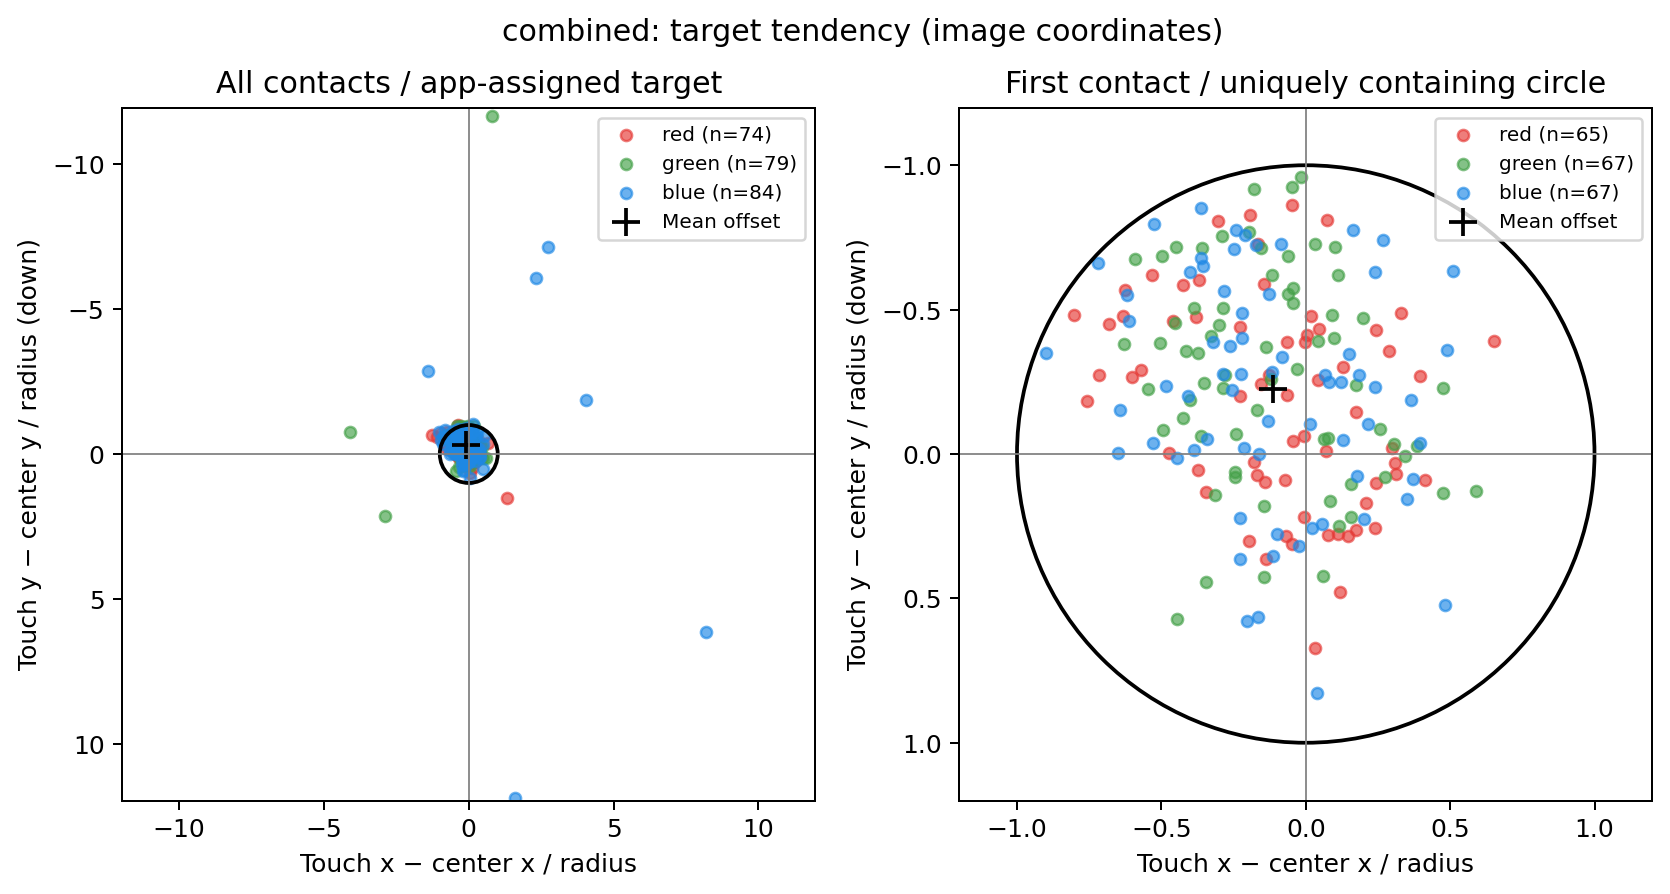

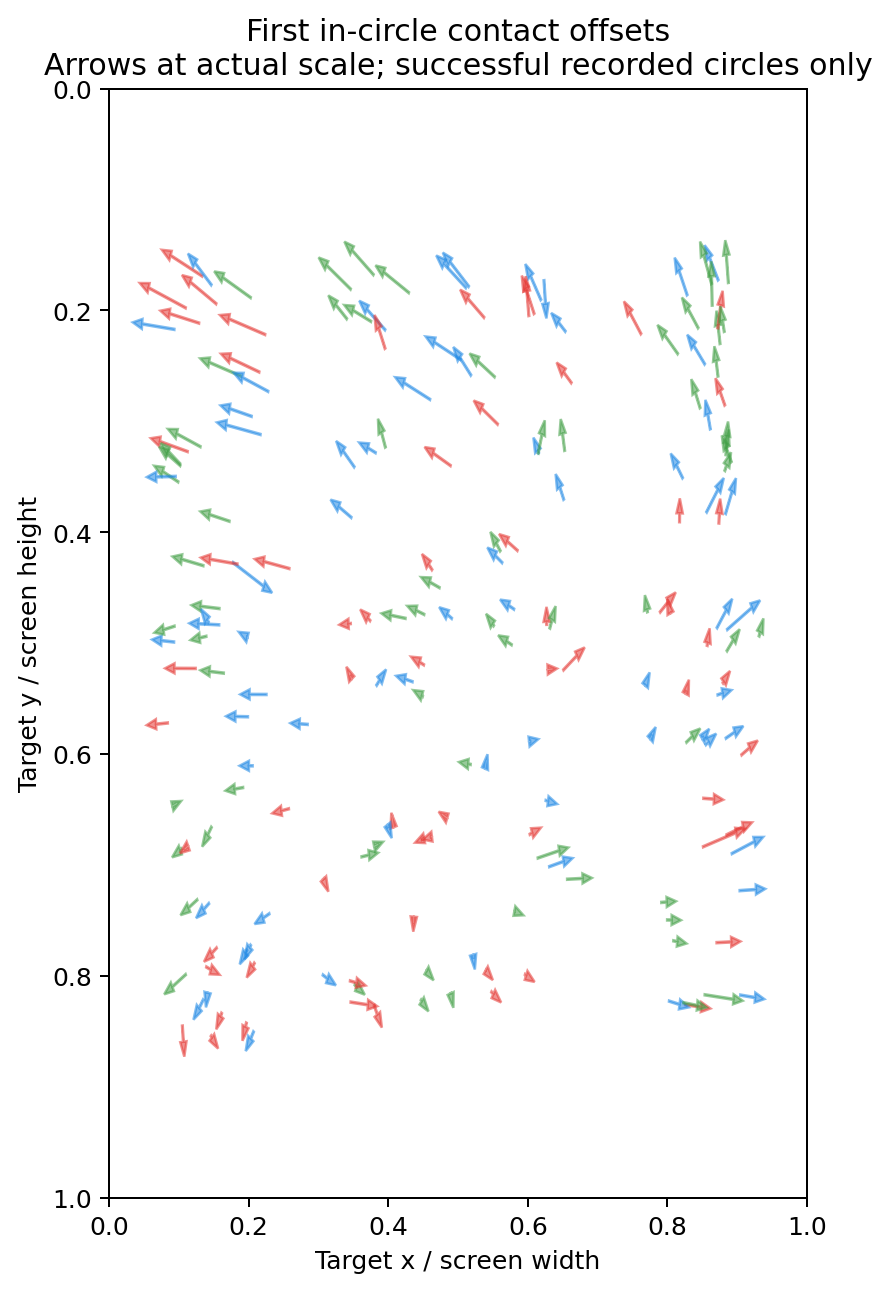

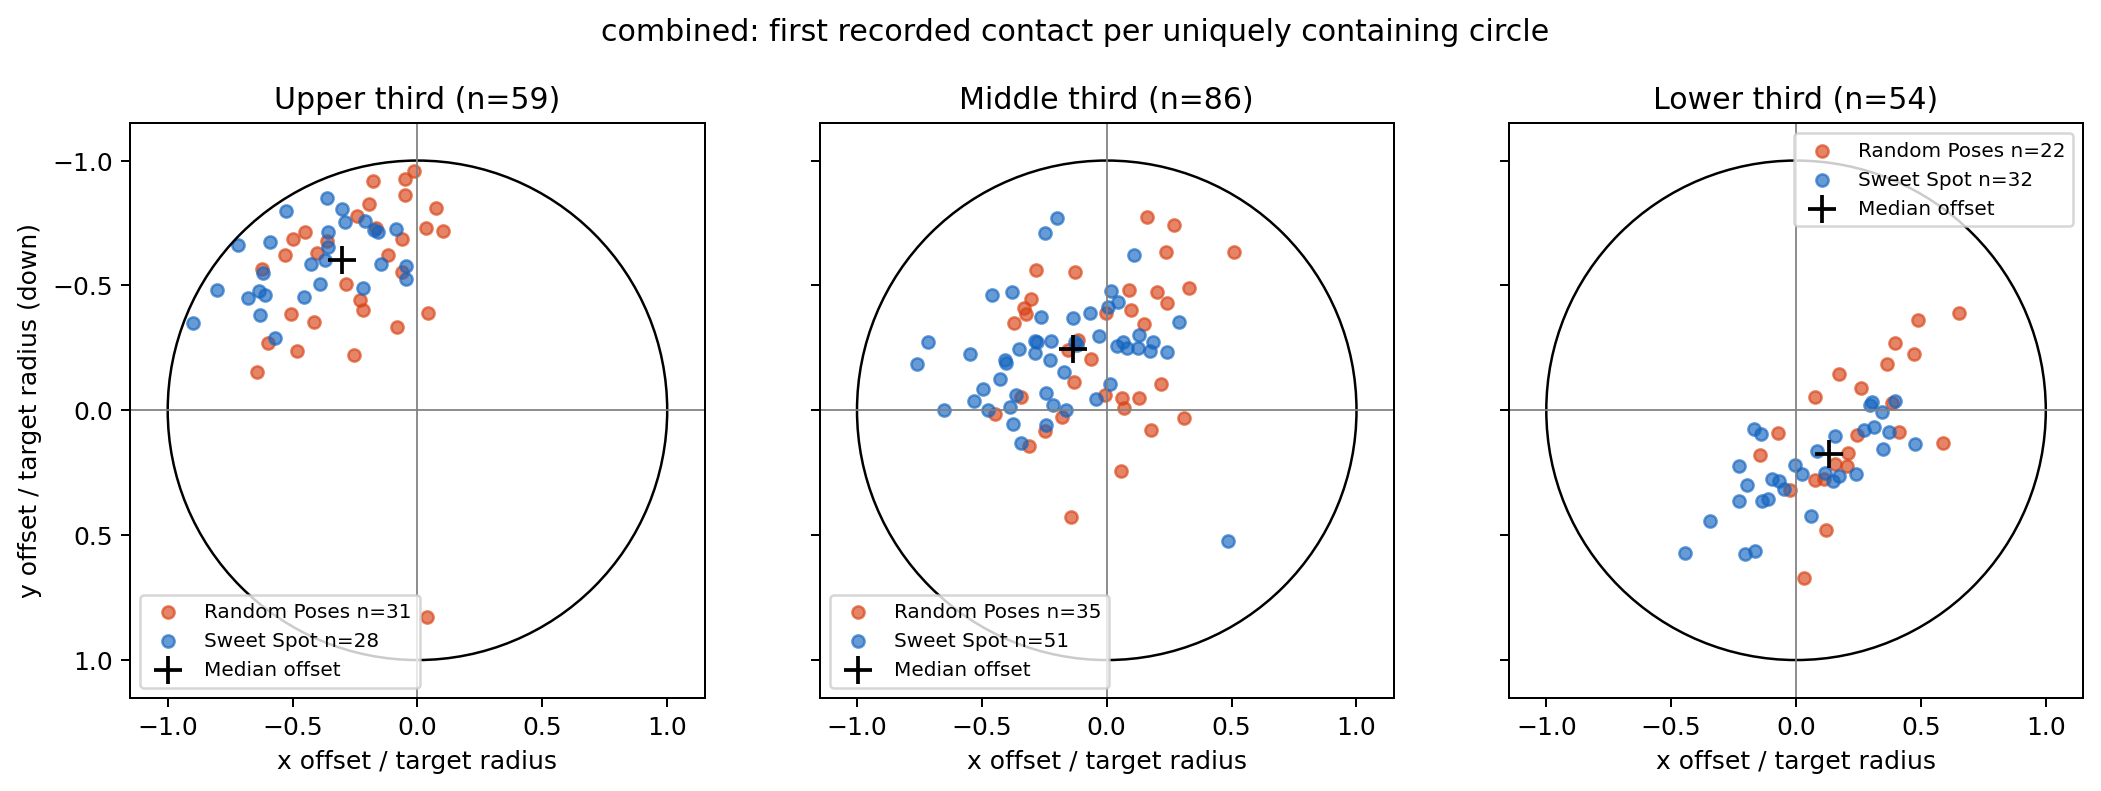

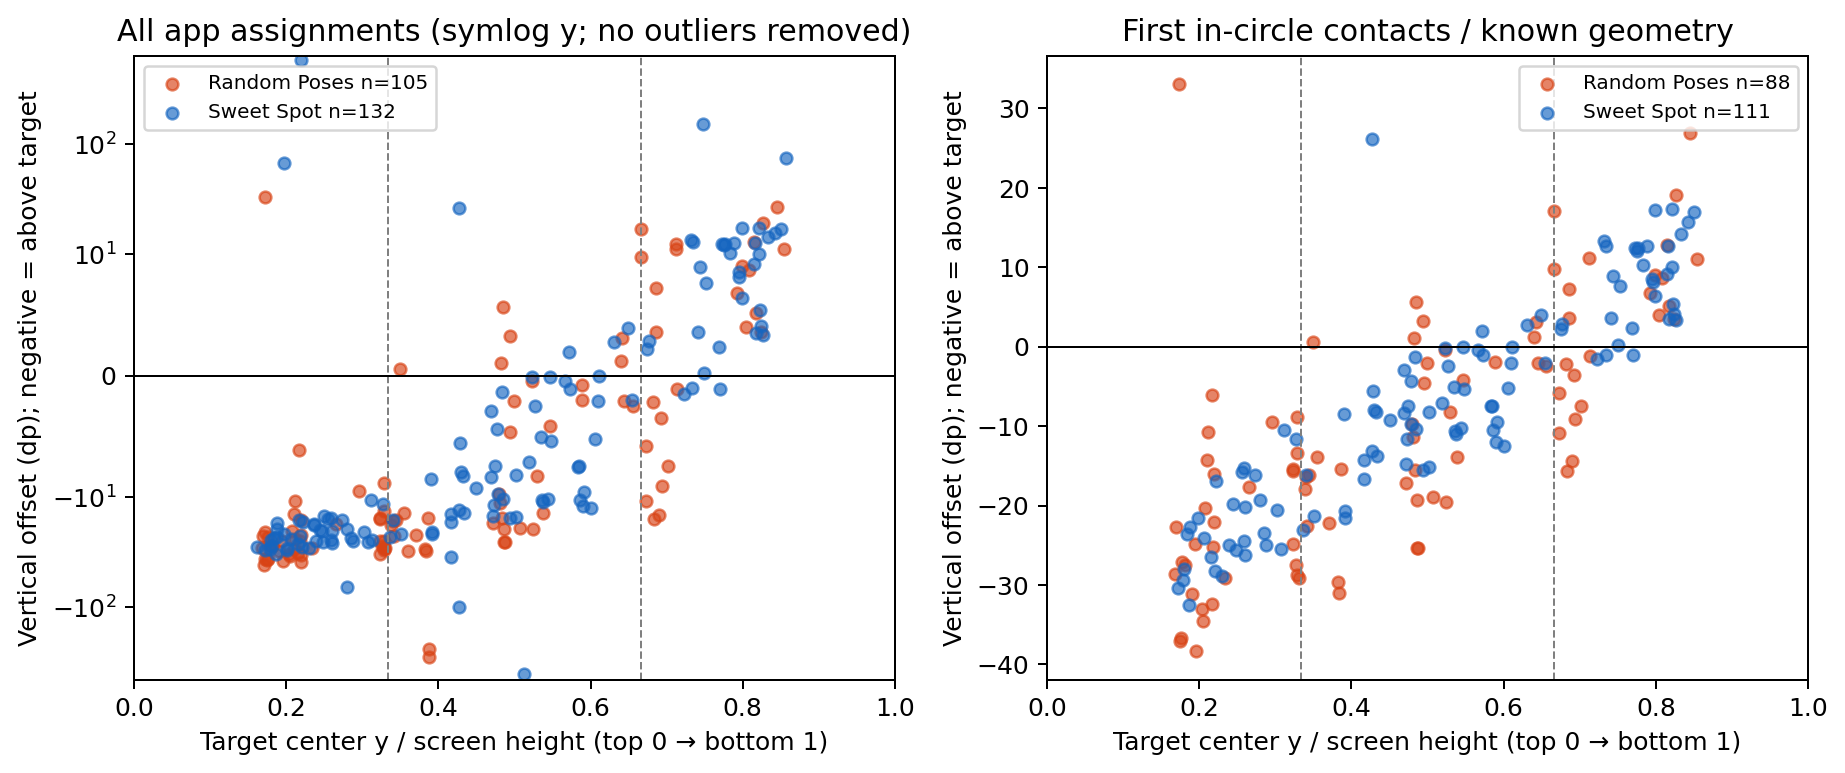

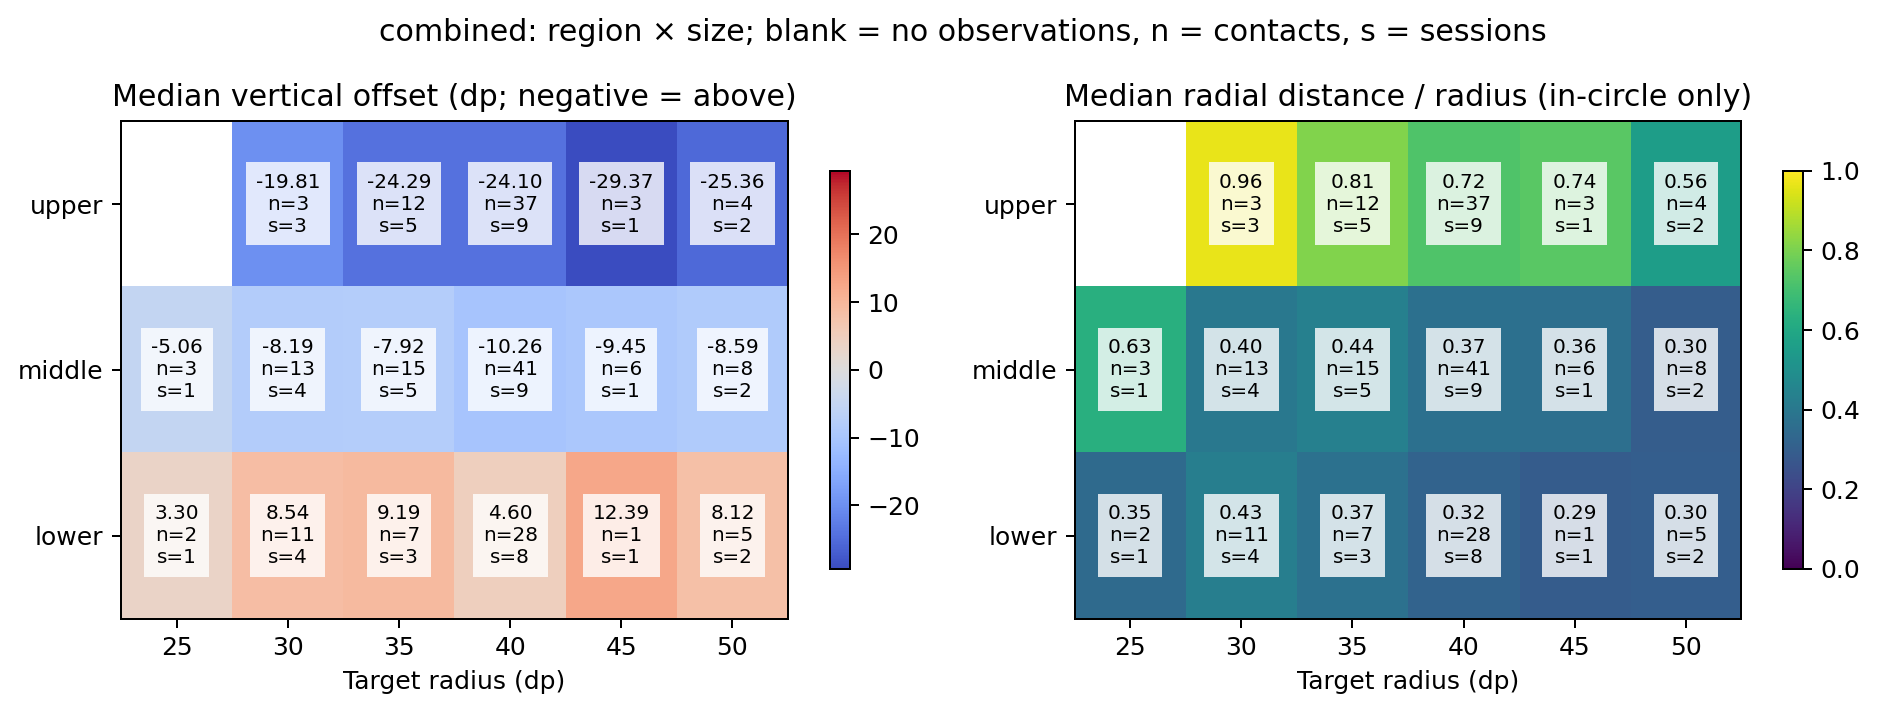

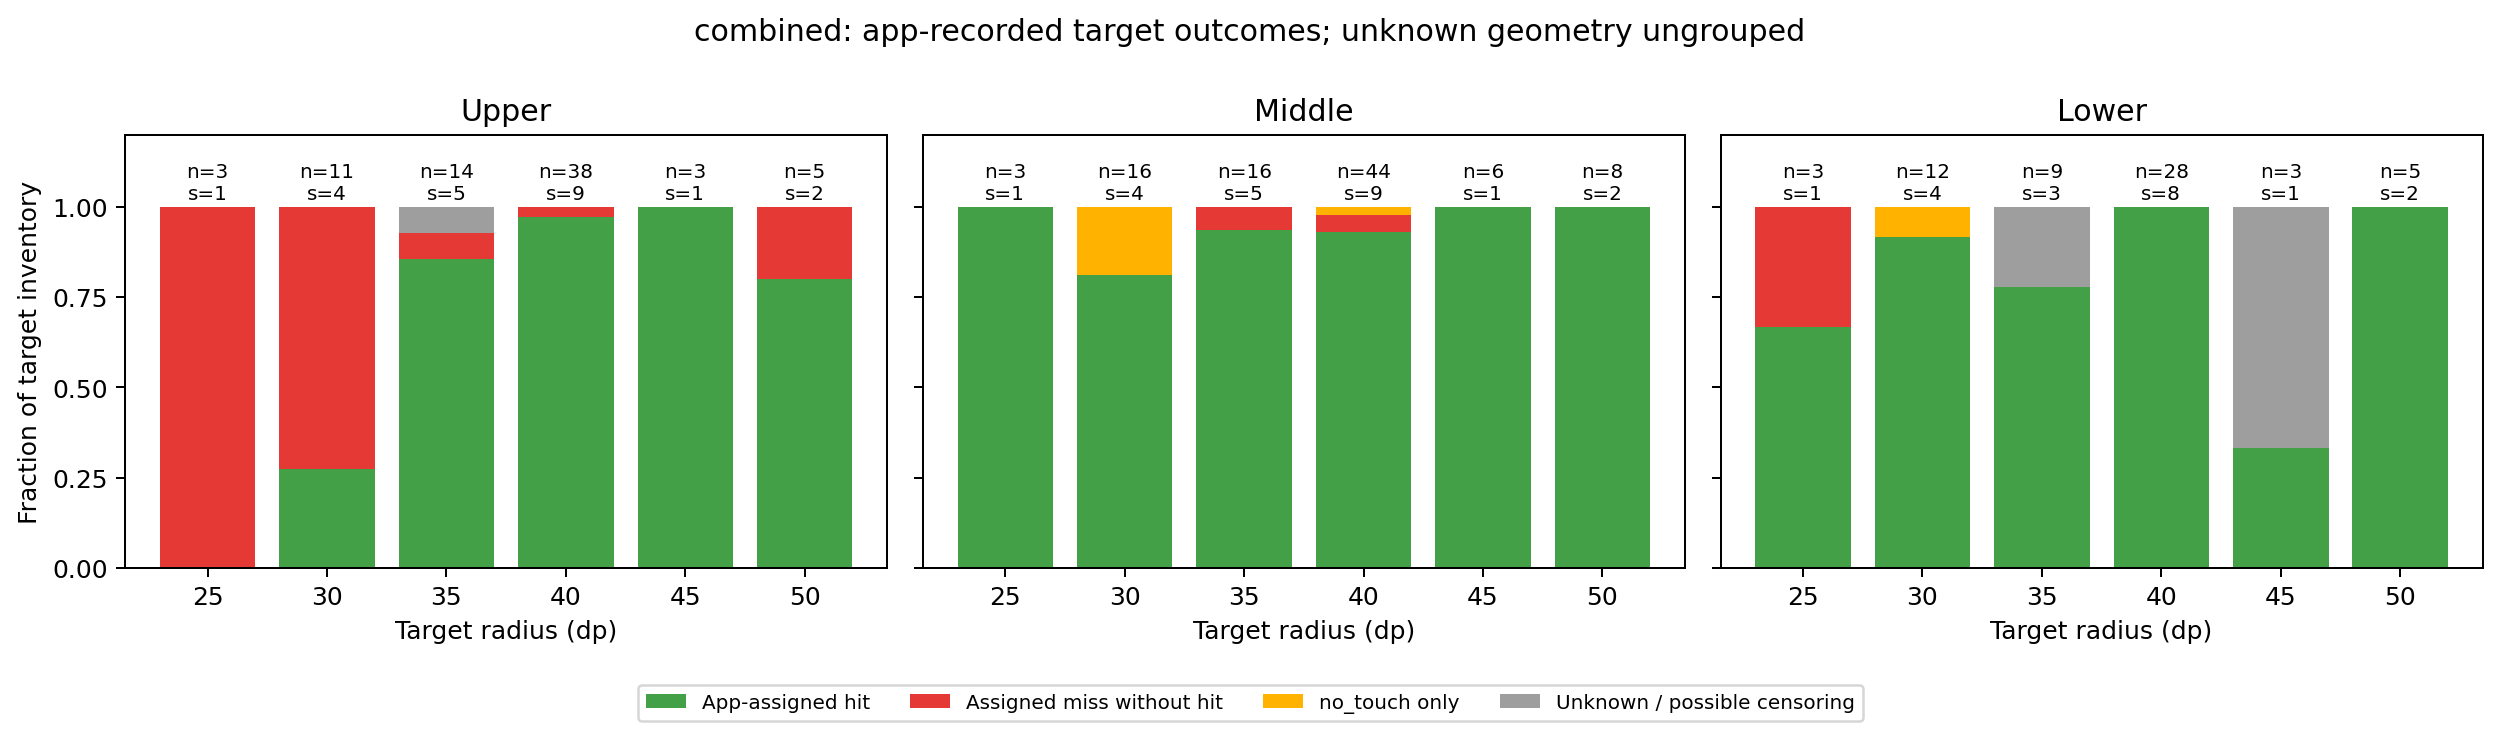

In [2]:
for dataset, report in zip(('sweetspot', 'random_poses', 'combined'), reports):
    display(Markdown(report))
    for name in ('target_tendency', 'screen_bias', 'region_tendency', 'vertical_bias_by_height', 'region_by_size', 'target_outcomes_region_by_size'):
        display(Image(filename=str(ROOT / 'results' / dataset / 'figures' / f'{name}.png')))
    if dataset != 'combined':
        display(Image(filename=str(ROOT / 'results' / dataset / 'figures/imu_and_bias.png')))
    if dataset == 'random_poses':
        display(Image(filename=str(ROOT / 'results' / dataset / 'maps/session_overview.png')))